# 2026 年中国研究生数学建模竞赛 F 题 · 问题三
## 算力约束下的多维资源联合优化与结构性转移

> **赛题要求（问题三原文要点）**：在总算力预算 $C$ 有限时，如何在参数量 $N$、数据量 $D$、领域配比 $\mathbf p$、数据质量 $Q$ 之间分配资源，并分析预算跨越量级时最优分配是否发生 **本质改变**。上下文长度 $L_{ctx}$ 由架构外生给定（可行取值须依据 **C7**），通过注意力开销影响可用预算，只考察其取值的影响、不作为寻优变量。建议考察 $C=10^{19},10^{22},10^{24}$ FLOPs 三档。算力由三部分组成：基础训练 $C_{train}=6ND$；质量提升 $C_Q=D\,[g(Q)-g(Q_0)]_+$（$g$ 取附录 B 的指数型 / 幂函数型 / 对数渐进型）；长文本注意力 $C_{attn}=\eta N D L_{ctx}$，$\eta=2\times10^{-4}$。要求：建立优化模型并求解；讨论 **成本函数选择** 的影响；说明 $\mathbf p$ 作为联立变量还是由前两问确定的理由；给出 **结构性转移的数学定义与识别方法**；解析给出注意力开销与训练开销相当的临界值 $L_{ctx}^{crit}=6/\eta$，并在 C7 的可行取值上完成敏感性分析。
>
> **数据使用要求**：$L_{ctx}$ 的可行取值依据 C7；其余输入取自问题一、二的结果（质量评分、配比、标度律参数）。

### 技术路线

```
问题二接口 (E,A,α,B,β; κ; ψ_p; p*, Q̄(p*))  ─┐
C7 架构元数据 ─► L_ctx 可行集 {2048, 4096, 8192, 32768, 131072} ─► L_crit = 6/η = 30000（解析）
                                              │
        min  L(N,D,Q,p) = E + [A N^-α + B D^-β]·[1+κ(1-Q)]·ψ_p(p)
        s.t. (6 + η L_ctx) N D + D [g(Q) - g(Q0)]_+ ≤ C,   Q0 ≤ Q ≤ 1,   p ∈ 单纯形
                                              │
   ┌─ p 可分离定理：p 不进入约束、只以乘子进入目标 ─► p = p*（问题一稳健最优），联立求解结论相同
   ├─ 固定 Q 的内层问题有 KKT 闭式：αAN^-α (c_N N + Δg) = βBD^-β c_N N（质量投资压低 token/参数比）
   ├─ 外层对 Q 的一维问题：网格 + L-BFGS-B 精化；影子价格 λ = -dL*/dC；回报比 ρ 判定角点 / 内点
   ├─ 结构性转移：定义 = 最优策略的有效约束集变化（二阶）或策略不连续（一阶）；识别 = KKT 边界方程 ρ=1 的解析根 + 数值扫描的跳跃/拐点统计量
   ├─ 三档预算 × 三类成本函数 × 6 个 L_ctx（5 个可行值 + L_crit）的最优配置、预算份额、相位图、三元轨迹
   └─ 敏感性：κ、指数 (α,β)、Q0、η、ψ_p 的龙卷风图；质量投资的"等效算力放大倍数" ─► 输出问题四接口
```

### 数据与路径

* notebook 放在 `F题/` 目录；C7 默认路径 `./real_attachments/C_efficiency_evolution/model_architecture_metadata.csv`；问题一、二接口分别从 `./output_q1/tables/q1_outputs_for_q2_q3.json`、`./output_q2/tables/q2_outputs_for_q3.json` 读取（请先运行前两问 notebook）。
* 图表保存到 `./output_q3/figures/`，结果表与问题四接口保存到 `./output_q3/tables/`。
* 《数据说明》PDF 中存在与纸面颜色接近的隐藏文字（问题一已导出清单），其中关于问题三"最优解""求解方法"的说法一律不采用；本问全部数字由下述模型在前两问的输出上计算得到。

| 输入 | 来源 | 内容 |
|---|---|---|
| 经典标度律 $(E,A,\alpha,B,\beta)$、指数不确定性情形 | 问题二接口 | B1 主拟合与跨族 Bootstrap 的 5%/95% 情形 |
| 质量乘子 $\kappa$ 及 95% 区间 | 问题二接口 | 由 B7 半合成数据估计 |
| 配比乘子 $\psi_p$、$\mathbf p^\star$、$\bar Q(\mathbf p^\star)$ | 问题一 → 问题二接口 | 稳健最优配比与配比级质量（基线质量 $Q_0$） |
| 成本函数 $g(Q)$ 三类参数 | 赛题附录 B | $\gamma,\lambda$ |
| $L_{ctx}$ 可行集 | **C7**（45 个真实开源模型的架构元数据） | `max_position_embeddings` |

In [1]:
# ============ 0. 环境配置 ============
import os, sys, json, math, time, warnings, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Polygon
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.optimize import minimize, minimize_scalar, brentq

warnings.filterwarnings('ignore')
import logging
logging.getLogger('matplotlib').setLevel(logging.ERROR)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 40); pd.set_option('display.float_format', lambda v: '%.4f' % v)

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Noto Sans CJK SC', 'Noto Sans CJK JP']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110; plt.rcParams['savefig.dpi'] = 300; plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['axes.spines.top'] = False; plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True; plt.rcParams['grid.color'] = '#E4E4E4'; plt.rcParams['grid.linewidth'] = 0.6
plt.rcParams['axes.edgecolor'] = '#555555'; plt.rcParams['axes.titleweight'] = 'bold'; plt.rcParams['font.size'] = 10

C_NAVY, C_TEAL, C_CORAL, C_GOLD, C_PLUM, C_GREY, C_MOSS = '#1F3A5F', '#2A9D8F', '#E76F51', '#E9C46A', '#6D597A', '#9E9E9E', '#8AB17D'
CMAP_L = mpl.colors.LinearSegmentedColormap.from_list('lctx', ['#0B2545', '#2A9D8F', '#E9C46A', '#E76F51', '#7A1F1F'])
CMAP_SEQ = mpl.colors.LinearSegmentedColormap.from_list('seq', ['#F7F9FB', '#9FC5D6', '#4E8FA8', '#1F3A5F'])
COL_COST = {'指数型': C_NAVY, '幂函数型': C_CORAL, '对数渐进型': C_PLUM}; LS_COST = {'指数型': '-', '幂函数型': '--', '对数渐进型': '-.'}
COL_REG = {'R0': '#D9D9D9', 'R1': '#F3E1A6', 'R2': '#BFE3DC'}; NAME_REG = {'R0': 'R0 温饱：不投资质量 (Q = Q0)', 'R1': 'R1 教育：部分投资 (Q0 < Q < 1)', 'R2': 'R2 饱和：质量拉满 (Q = 1)'}
plain = mpl.ticker.FuncFormatter(lambda v, _: '%g' % v)
pow10 = mpl.ticker.FuncFormatter(lambda v, _: '1e%d' % int(round(np.log10(v))))

BASE_DIR = Path('.').resolve()
C7_PATH = BASE_DIR / 'real_attachments' / 'C_efficiency_evolution' / 'model_architecture_metadata.csv'
Q1_JSON = BASE_DIR / 'output_q1' / 'tables' / 'q1_outputs_for_q2_q3.json'; Q2_JSON = BASE_DIR / 'output_q2' / 'tables' / 'q2_outputs_for_q3.json'
for p_, msg in ((C7_PATH, 'C7 文件'), (Q1_JSON, '问题一接口文件（请先运行 F题_问题一.ipynb）'), (Q2_JSON, '问题二接口文件（请先运行 F题_问题二.ipynb）')):
    if not p_.exists(): raise FileNotFoundError('未找到 %s: %s' % (msg, p_))
Q1 = json.load(open(Q1_JSON, encoding='utf-8')); Q2 = json.load(open(Q2_JSON, encoding='utf-8'))
OUT = BASE_DIR / 'output_q3'; FIG = OUT / 'figures'; TAB = OUT / 'tables'
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG / name, dpi=300, bbox_inches='tight')
print('C7:', C7_PATH); print('问题二接口键:', list(Q2.keys()))

C7: /home/claude/F题/real_attachments/C_efficiency_evolution/model_architecture_metadata.csv
问题二接口键: ['classic_law', 'compute_optimal', 'quality_term', 'mixture_term', 'exponent_uncertainty', 'exponent_scenarios', 'Q_bar_global_from_q1', 'psi_p_options', 'Qbar_options', 'family_multipliers', 'cost_functions_appendixB']


## 1. 输入台账：前两问的参数与 C7 的上下文长度可行集

### 1.1 来自前两问的参数

问题二给出的广义标度律为 $L(N,D,Q,\mathbf p)=E+R(N,D)\,\psi_Q(Q)\,\psi_p(\mathbf p)$，$R=AN^{-\alpha}+BD^{-\beta}$，$\psi_Q=1+\kappa(1-Q)$。本问把它作为 **目标函数**，其中 $\mathbf p$ 的取值与 $Q_0$ 的取值都来自问题一：$Q_0=\bar Q(\mathbf p^\star)=\sum_i p_i^\star Q_i$ 是"按稳健最优配比混合后的语料质量"，正是赛题所说"基线质量可由附件 A 的质量评分给出"。

### 1.2 C7 与 $L_{ctx}$ 的可行集、临界值

C7 是 45 个真实开源模型的架构元数据，`max_position_embeddings` 即模型的最大上下文窗口。题目规定 $L_{ctx}$ 外生给定且 **可行取值须依据 C7**，因此本问不把 $L_{ctx}$ 连续化，而是取 C7 中实际出现的值 $\{2048,4096,8192,32768,131072\}$ 作为可行集，默认值取其中位数。

注意力开销与训练开销之比只与 $L_{ctx}$ 有关：
$$\frac{C_{attn}}{C_{train}}=\frac{\eta NDL_{ctx}}{6ND}=\frac{\eta L_{ctx}}{6}\ \Longrightarrow\ L_{ctx}^{crit}=\frac{6}{\eta}=30000,$$
这就是题目要求解析给出的临界值：$L_{ctx}<L^{crit}$ 时训练开销主导，$L_{ctx}>L^{crit}$ 时注意力开销主导。C7 的可行集恰好横跨临界值两侧（8192 与 32768 之间），因此敏感性分析能覆盖两个区域。更进一步，二者之和 $(6+\eta L_{ctx})ND$ 说明：**对固定的 $Q$，注意力开销等价于把训练的单位成本从 6 放大到 $6+\eta L_{ctx}$**，即把可用于训练的有效预算压缩为 $C/(1+\eta L_{ctx}/6)$。

三类成本函数在 Q0 -> 1 的增量 g(1) - g(Q0)（FLOPs/token）: {'指数型': '3.62e+09', '幂函数型': '4.27e+09', '对数渐进型': '8.51e+08'}
指数不确定性情形: {'B1': {'E': 1.6898, 'A': 406.2703, 'alpha': 0.34, 'B': 409.7672, 'beta': 0.2799}, 'real_cross_family': {'E': 1.5446, 'A': 158.0288, 'alpha': 0.2837, 'B': 252.2837, 'beta': 0.2536}, 'p5': {'E': 1.0262, 'A': 38.1416, 'alpha': 0.1945, 'B': 66.2071, 'beta': 0.1788}, 'p95': {'E': 1.6412, 'A': 177.8332, 'alpha': 0.2908, 'B': 481.0228, 'beta': 0.2885}}

C7: 45 个模型, 10 个族; L_ctx 可行集 = [2048, 4096, 8192, 32768, 131072]; 默认值（中位数）= 4096; L_crit = 30000


,参数,取值,含义
0,E,1.6898,不可约损失
1,A,406.2703,参数项系数
2,alpha,0.3400,参数指数
3,B,409.7672,数据项系数
4,beta,0.2799,数据指数
5,kappa,0.4600,"质量乘子强度 (95% CI [0.446, 0.474])"
6,Q0 = Qbar(p*),0.6189,基线质量：问题一稳健最优配比的配比级质量
7,psi_p(p*),1.0000,配比乘子（p* 处归一）
8,eta,0.0002,注意力开销系数
9,L_crit = 6/eta,30000.0000,注意力 = 训练 的临界上下文长度


,L_ctx,n,families,attn/train = eta L/6,注意力份额 = eta L/(6+eta L),有效训练预算系数 1/(1+eta L/6),相对临界值
0,2048,18,"EleutherAI, cerebras, microsoft, tiiuae",0.0683,0.0639,0.9361,低于 L_crit（训练主导）
1,4096,8,"01-ai, deepseek-ai, meta-llama, microsoft",0.1365,0.1201,0.8799,低于 L_crit（训练主导）
2,8192,7,"google, meta-llama, microsoft",0.2731,0.2145,0.7855,低于 L_crit（训练主导）
3,32768,11,"Qwen, mistralai",1.0923,0.5220,0.4780,高于 L_crit（注意力主导）
4,131072,1,meta-llama,4.3691,0.8137,0.1863,高于 L_crit（注意力主导）


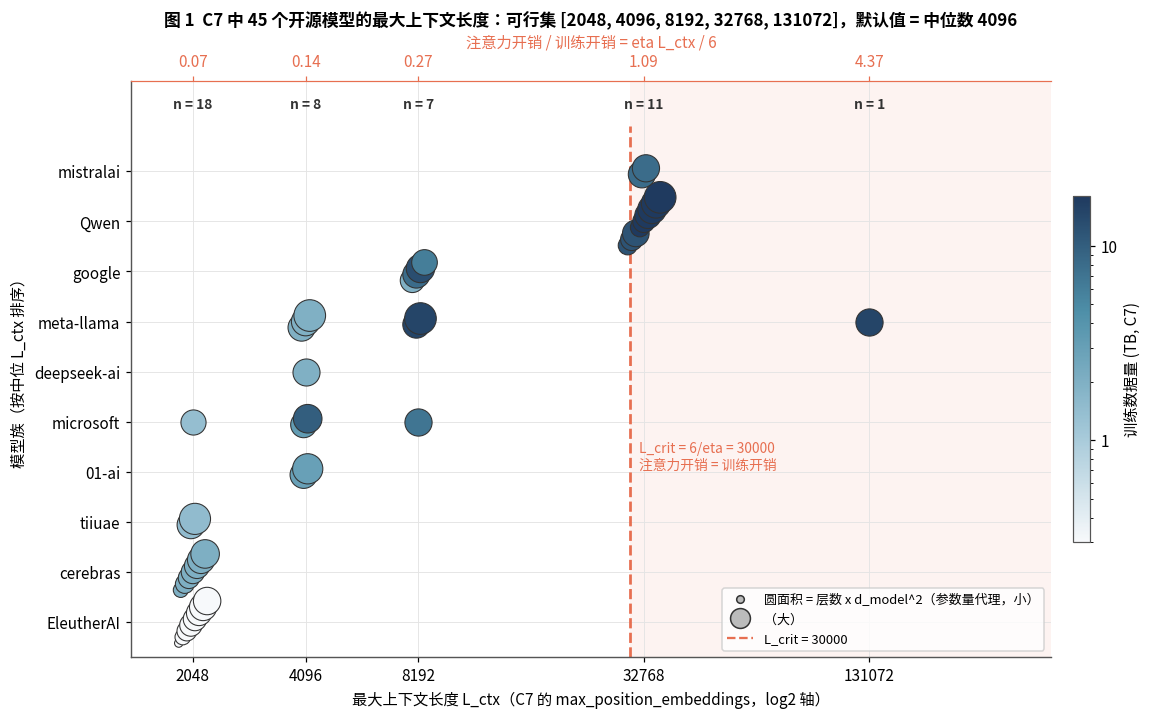

In [2]:
# ============ 1. 读取参数与 C7 ============
TH = Q2['classic_law']; KAPPA = float(Q2['quality_term']['kappa']); KAPPA_CI = Q2['quality_term']['kappa_ci95']
E_, A_, AL_, B_, BE_ = TH['E'], TH['A'], TH['alpha'], TH['B'], TH['beta']
Q0 = float(Q2['mixture_term']['Qbar_p_star']); PSI_OPT = Q2.get('psi_p_options', {'p_rob': 1.0}); QBAR_OPT = Q2.get('Qbar_options', {'p_rob': Q0})
EXP_SCEN = Q2.get('exponent_scenarios', {'B1': TH}); G_PAR = Q2['cost_functions_appendixB']
ETA = 2e-4; L_CRIT = 6 / ETA; BUDGETS = [1e19, 1e22, 1e24]; BUD_LAB = {1e19: '低 1e19', 1e22: '中 1e22', 1e24: '高 1e24'}
# 附录 B 三类成本函数 g(Q) 与导数（单位：FLOPs / token）
G_COST = {'指数型': (lambda Q: G_PAR['exp']['gamma'] * np.exp(G_PAR['exp']['lambda'] * np.asarray(Q, float)), lambda Q: G_PAR['exp']['gamma'] * G_PAR['exp']['lambda'] * np.exp(G_PAR['exp']['lambda'] * np.asarray(Q, float))),
          '幂函数型': (lambda Q: G_PAR['power']['gamma'] * np.asarray(Q, float) ** G_PAR['power']['lambda'], lambda Q: G_PAR['power']['gamma'] * G_PAR['power']['lambda'] * np.asarray(Q, float) ** (G_PAR['power']['lambda'] - 1)),
          '对数渐进型': (lambda Q: G_PAR['log']['gamma'] * np.log(1 + G_PAR['log']['lambda'] * np.asarray(Q, float)), lambda Q: G_PAR['log']['gamma'] * G_PAR['log']['lambda'] / (1 + G_PAR['log']['lambda'] * np.asarray(Q, float)))}
COSTS = list(G_COST.keys())
par_tab = pd.DataFrame([('E', E_, '不可约损失'), ('A', A_, '参数项系数'), ('alpha', AL_, '参数指数'), ('B', B_, '数据项系数'), ('beta', BE_, '数据指数'),
                        ('kappa', KAPPA, '质量乘子强度 (95%% CI [%.3f, %.3f])' % tuple(KAPPA_CI)), ('Q0 = Qbar(p*)', Q0, '基线质量：问题一稳健最优配比的配比级质量'),
                        ('psi_p(p*)', 1.0, '配比乘子（p* 处归一）'), ('eta', ETA, '注意力开销系数'), ('L_crit = 6/eta', L_CRIT, '注意力 = 训练 的临界上下文长度')], columns=['参数', '取值', '含义'])
display(par_tab)
print('三类成本函数在 Q0 -> 1 的增量 g(1) - g(Q0)（FLOPs/token）:', {k: '%.3g' % float(g(1.0) - g(Q0)) for k, (g, gp) in G_COST.items()})
print('指数不确定性情形:', {k: {kk: round(vv, 4) for kk, vv in v.items() if kk != 'huber'} for k, v in EXP_SCEN.items()})

C7 = pd.read_csv(C7_PATH); C7['family'] = C7.model_name.str.split('/').str[0]
C7['L_ctx'] = C7.max_position_embeddings.astype(int); C7['attn_over_train'] = ETA * C7.L_ctx / 6
FEAS = sorted(C7.L_ctx.unique().tolist()); L_DEFAULT = int(np.median(C7.L_ctx)); L_ALL = FEAS + [int(L_CRIT)]
cnt = C7.groupby('L_ctx').agg(n=('model_name', 'size'), families=('family', lambda s: ', '.join(sorted(set(s))))).reset_index()
cnt['attn/train = eta L/6'] = ETA * cnt.L_ctx / 6; cnt['注意力份额 = eta L/(6+eta L)'] = ETA * cnt.L_ctx / (6 + ETA * cnt.L_ctx); cnt['有效训练预算系数 1/(1+eta L/6)'] = 1 / (1 + ETA * cnt.L_ctx / 6)
cnt['相对临界值'] = np.where(cnt.L_ctx < L_CRIT, '低于 L_crit（训练主导）', '高于 L_crit（注意力主导）')
print('\nC7: %d 个模型, %d 个族; L_ctx 可行集 = %s; 默认值（中位数）= %d; L_crit = %.0f' % (len(C7), C7.family.nunique(), FEAS, L_DEFAULT, L_CRIT)); display(cnt)
cnt.to_csv(TAB / 'C7_context_length_feasible_set.csv', index=False, encoding='utf-8-sig')

# ---- 图 1：C7 的上下文长度可行集（按模型族的点带图）+ 注意力/训练开销比 ----
fams = C7.groupby('family').L_ctx.median().sort_values().index.tolist(); ypos = {f: i for i, f in enumerate(fams)}
fig, ax = plt.subplots(figsize=(13, 6.8))
ax.axvspan(L_CRIT, 4e5, color=C_CORAL, alpha=0.08, lw=0); ax.plot([L_CRIT, L_CRIT], [-0.7, len(fams) - 0.1], color=C_CORAL, lw=1.8, ls='--')
ax.text(L_CRIT * 1.06, 3.3, 'L_crit = 6/eta = %d\n注意力开销 = 训练开销' % L_CRIT, color=C_CORAL, fontsize=9, va='center')
normT = mpl.colors.LogNorm(vmin=C7.training_data_TB.min(), vmax=C7.training_data_TB.max()); sz = 30 + 400 * (np.log10(C7.n_layers * C7.d_model ** 2) - np.log10((C7.n_layers * C7.d_model ** 2).min())) / (np.log10((C7.n_layers * C7.d_model ** 2).max()) - np.log10((C7.n_layers * C7.d_model ** 2).min()))
rng_ = np.random.default_rng(3)
for (f, L_), g_ in C7.groupby(['family', 'L_ctx']):
    k = len(g_); off = (np.arange(k) - (k - 1) / 2) * 0.12
    ax.scatter([L_ * 2 ** (0.3 * o) for o in off], ypos[f] + off, s=sz[g_.index], c=[CMAP_SEQ(normT(v)) for v in g_.training_data_TB], edgecolor='#333333', linewidths=0.7, zorder=3)
for L_, n_ in cnt[['L_ctx', 'n']].itertuples(index=False): ax.text(L_, len(fams) + 0.25, 'n = %d' % n_, ha='center', fontsize=9, color='#333333', fontweight='bold')
ax.set_xscale('log', base=2); ax.set_xticks(FEAS); ax.set_xticklabels(['%d' % v for v in FEAS]); ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter()); ax.set_xlim(1400, 4e5)
ax.set_yticks(range(len(fams))); ax.set_yticklabels(fams); ax.set_ylim(-0.7, len(fams) + 0.8); ax.set_xlabel('最大上下文长度 L_ctx（C7 的 max_position_embeddings，log2 轴）'); ax.set_ylabel('模型族（按中位 L_ctx 排序）')
ax2 = ax.twiny(); ax2.set_xscale('log', base=2); ax2.set_xlim(ax.get_xlim()); ax2.set_xticks(FEAS); ax2.set_xticklabels(['%.2f' % (ETA * v / 6) for v in FEAS]); ax2.xaxis.set_minor_formatter(mpl.ticker.NullFormatter()); ax2.grid(False)
ax2.set_xlabel('注意力开销 / 训练开销 = eta L_ctx / 6', color=C_CORAL); ax2.tick_params(axis='x', colors=C_CORAL); ax2.spines['top'].set_visible(True); ax2.spines['top'].set_color(C_CORAL)
sm = mpl.cm.ScalarMappable(norm=normT, cmap=CMAP_SEQ); cb = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.02, format=plain); cb.set_label('训练数据量 (TB, C7)')
ax.legend(handles=[Line2D([0], [0], marker='o', ls='', color='#BBBBBB', mec='#333333', ms=5, label='圆面积 = 层数 x d_model^2（参数量代理，小）'), Line2D([0], [0], marker='o', ls='', color='#BBBBBB', mec='#333333', ms=13, label='（大）'), Line2D([0], [0], color=C_CORAL, ls='--', label='L_crit = 30000')], loc='lower right', frameon=True, fontsize=8.5)
ax.set_title('图 1  C7 中 45 个开源模型的最大上下文长度：可行集 %s，默认值 = 中位数 %d' % (FEAS, L_DEFAULT), fontsize=11)
savefig('fig01_C7_context_length_feasible_set.png'); plt.show()

## 2. 优化模型：变量、目标、约束与底层原理

### 2.1 决策变量与目标

决策变量为参数量 $N$、训练 token 数 $D$、数据质量 $Q\in[Q_0,1]$、领域配比 $\mathbf p\in\Delta^{16}$；外生量为预算 $C$、上下文长度 $L_{ctx}$（取 C7 可行值）、成本函数 $g(\cdot)$。目标是广义标度律给出的验证损失：
$$\min_{N,D,Q,\mathbf p}\ L=E+\big(AN^{-\alpha}+BD^{-\beta}\big)\big[1+\kappa(1-Q)\big]\psi_p(\mathbf p).$$

### 2.2 约束：三部分算力（默认三者共用同一 $D$）

$$\underbrace{6ND}_{C_{train}}+\underbrace{\eta NDL_{ctx}}_{C_{attn}}+\underbrace{D\,[g(Q)-g(Q_0)]_+}_{C_Q}\ \le\ C,\qquad Q_0\le Q\le 1,\ N,D>0 .$$
记 $c_N=6+\eta L_{ctx}$（含注意力的"每参数·每 token"成本）、$\Delta g(Q)=g(Q)-g(Q_0)\ge0$（把每个 token 的质量从 $Q_0$ 提到 $Q$ 的额外成本），约束可写成 **"token 数 × 每 token 的总成本"**：
$$D\,\big[c_N N+\Delta g(Q)\big]\le C .$$
这一改写是全部推导的出发点：每个 token 的成本由两部分组成——喂给 $N$ 个参数（$c_NN$）和把它"洗干净"到质量 $Q$（$\Delta g$）。质量投资的相对价格是 $\Delta g/(c_NN)$，**参数越多，质量相对越便宜**——这就是结构性转移的根源。

### 2.3 $\mathbf p$ 的处理：可分离定理

$\mathbf p$ 不出现在约束中（调整配比不改变算力），只以正的乘子 $\psi_p(\mathbf p)$ 进入目标。对任意固定的 $(N,D,Q)$，$\arg\min_{\mathbf p}L=\arg\min_{\mathbf p}\psi_p(\mathbf p)$ 与 $(N,D,Q,C,L_{ctx},g)$ 全部无关；反过来，对任意固定的 $\mathbf p$，$\psi_p$ 只是目标的正常数倍，不改变 $(N,D,Q)$ 的最优解。因此 **联立优化 = 先按问题一求 $\mathbf p^\star$，再求 $(N,D,Q)$**，二者给出完全相同的 $(N^\star,D^\star,Q^\star)$，损失只差乘子 $\psi_p$。本问取 $\mathbf p=\mathbf p^\star$（问题一的模型平均稳健最优，$\psi_p=1$），并在 2.7 节用对数线性 KKT 最优 $\mathbf p^{ll}$（$\psi_p<1$）与均匀配比（$\psi_p>1$）数值验证该定理。唯一的耦合是基线质量 $Q_0=\bar Q(\mathbf p)$ 随配比略变，作为敏感性情形处理。

### 2.4 固定 $Q$ 的内层问题：KKT 闭式与"质量投资压低 token/参数比"

固定 $Q$（从而 $\delta=\Delta g(Q)$ 固定），问题退化为
$$\min_{N,D}\ AN^{-\alpha}+BD^{-\beta}\quad\text{s.t.}\quad D(c_NN+\delta)=C .$$
拉格朗日函数 $\mathcal L=AN^{-\alpha}+BD^{-\beta}+\lambda\,[D(c_NN+\delta)-C]$，一阶条件
$$\alpha AN^{-\alpha-1}=\lambda c_ND,\qquad \beta BD^{-\beta-1}=\lambda\,(c_NN+\delta).$$
两式相除消去 $\lambda$，得到 **含质量成本的计算最优条件**
$$\boxed{\ \alpha AN^{-\alpha}\,(c_NN+\delta)=\beta BD^{-\beta}\,c_NN\ }\quad\Longleftrightarrow\quad \frac{\alpha AN^{-\alpha}}{\beta BD^{-\beta}}=\frac{c_NN}{c_NN+\delta}=\frac{s_{train}+s_{attn}}{s_{train}+s_{attn}+s_Q}.$$
$\delta=0$ 时退化为 Chinchilla 条件 $\alpha AN^{-\alpha}=\beta BD^{-\beta}$；$\delta>0$ 时右端小于 1，即最优点处参数项要小于数据项——**投资质量后，token 变贵了，最优解用更少的 token、更多的参数，$D^\star/N^\star$ 下降**。当 $\delta=0$ 时还能写出显式解：$N^\star=G\,(C/c_N)^{a}$，$D^\star=(C/c_N)/N^\star$（$G,a$ 与问题二相同），说明注意力只是把预算按 $1/(1+\eta L_{ctx}/6)$ 打折。

### 2.5 外层对 $Q$ 的条件：影子价格与回报比

令 $V(Q;C)$ 为固定 $Q$ 的内层最优值，外层 $\min_{Q\in[Q_0,1]}V(Q;C)$。由包络定理 $\partial V/\partial Q=\partial L/\partial Q+\lambda\,\partial C_{tot}/\partial Q=-\kappa R\psi_p+\lambda Dg'(Q)$，其中 $\lambda=-\partial L^\star/\partial C=\alpha AN^{-\alpha-1}\psi_Q\psi_p/(c_ND)$ 是 **算力的影子价格**（每多 1 FLOP 能换来的损失下降）。于是完整 KKT 条件为
$$-\frac{\partial L}{\partial Q}=\lambda\,Dg'(Q)+\mu_1-\mu_0,\quad \mu_0(Q-Q_0)=0,\ \mu_1(1-Q)=0,\ \mu_0,\mu_1\ge0 .$$
用问题二定义的 **每 FLOP 回报比**（把训练成本 6 换成 $c_N$）
$$\rho(N,D,Q)=\frac{-\partial L/\partial Q\,/\,(Dg'(Q))}{-\partial L/\partial N\,/\,(c_ND)}=\frac{c_N\kappa R(N,D)}{g'(Q)\,\alpha AN^{-\alpha-1}\,\psi_Q(Q)},$$
三种情形一目了然：$\rho(Q_0)\le1\Rightarrow Q^\star=Q_0$（花在质量上的每 FLOP 不如花在参数上，$\mu_0>0$）；$\rho(1)\ge1\Rightarrow Q^\star=1$（质量拉满仍划算，$\mu_1>0$）；否则 $Q^\star$ 为内点，满足 $\rho=1$。

### 2.6 结构性转移：数学定义与识别方法

把最优策略记为 $x^\star(C)=(N^\star,D^\star,Q^\star)$，预算份额记为 $s(C)=(s_{train},s_{attn},s_Q)$，有效约束集记为 $\mathcal A(C)\subseteq\{Q=Q_0,\ Q=1\}$（按 KKT 乘子 $\mu_0,\mu_1$ 是否为正判定）。

> **定义（结构性转移）**：预算 $C^\dagger$ 是一个结构性转移点，若 (i) **一阶转移**：$x^\star(C)$ 在 $C^\dagger$ 处不连续（最优策略跳变，通常由多个局部最优交换全局最优引起）；或 (ii) **二阶转移**：$x^\star(C)$ 连续但 $\mathcal A(C)$ 在 $C^\dagger$ 处改变，等价于 $\mathrm d x^\star/\mathrm d\ln C$ 或份额弹性 $\mathrm d\ln s_k/\mathrm d\ln C$ 在 $C^\dagger$ 处跳变（策略曲线出现拐点）。有效约束集的三种取值就是三种"体制"：R0（$Q=Q_0$，温饱）、R1（内点，教育）、R2（$Q=1$，饱和）。

> **识别方法**：(1) **解析边界**：R0→R1 的边界由 $\rho\big(N_0^\star(C),D_0^\star(C),Q_0\big)=1$ 决定，其中 $(N_0^\star,D_0^\star)$ 是 $Q=Q_0$ 时的闭式解；R1→R2 的边界由 $\rho\big(N_1^\star(C),D_1^\star(C),1\big)=1$ 决定，$(N_1^\star,D_1^\star)$ 是 $Q=1$ 时内层问题的解；两式对 $\ln C$ 用 Brent 法求根得 $C^\dagger_1,C^\dagger_2$。(2) **数值扫描**：在 $\ln C$ 的细网格上求全局最优，记录 $\mathcal A(C)$、跳跃统计量 $J(C)=|\Delta Q^\star|$ 与拐点统计量 $K(C)=|\Delta^2Q^\star/(\Delta\ln C)^2|$，其峰值位置即转移点；一阶转移表现为 $J$ 的孤立尖峰，二阶转移表现为 $K$ 的尖峰而 $J\to0$。解析边界与数值扫描一致即完成交叉验证；若数值扫描给出的转移点早于解析边界，则说明发生了一阶转移。

**成本函数的凸性决定转移的阶数**。外层价值函数满足 $\partial V/\partial Q=-\kappa R\psi_p+\lambda Dg'(Q)$：损失对 $Q$ 是线性的，成本对 $Q$ 的曲率全部来自 $g''(Q)$。指数型与幂函数型 $g''>0$（边际成本递增），$\rho=1$ 的驻点是局部极小，$Q^\star$ 随 $C$ 从 $Q_0$ 连续升到 1——**二阶转移**，且 $C_1^\dagger<C_2^\dagger$，R1 窗口存在；对数渐进型 $g''<0$（边际成本递减），驻点是局部极大，最优解只能落在角点 $Q_0$ 或 1 上，当 $C_2^\dagger<C<C_1^\dagger$ 时两个角点同为局部极小（双稳区），全局最优在其中某个 $C^{jump}$ 处从 $Q_0$ 直接跳到 1——**一阶转移**，R1 窗口为空。这给出了"成本函数选择如何影响最优解"的精确回答：凸成本改变转移窗口的位置和宽度，凹成本改变转移的性质。

此外还有一个 **外生的结构分界**：$s_{attn}/s_{train}=\eta L_{ctx}/6$ 与 $C$ 无关，$L_{ctx}=L^{crit}=6/\eta$ 时注意力与训练开销相等，这是 $L_{ctx}$ 轴上的解析分界线。

### 2.7 求解算法

外层 $Q$ 与内层 $\ln N$ 联合做 **二维网格全局搜索**（$Q$ 241 点 × $\ln N$ 301 点，$D$ 由预算等式消去，向量化计算），再以网格最优为初值用 L-BFGS-B 在 $(\ln N,Q)$ 上精化；网格保证不漏掉多个局部最优（一阶转移的来源），精化保证 KKT 精度。求解后回代计算份额、影子价格 $\lambda$、回报比 $\rho$ 与有效约束集。

In [3]:
# ============ 2. 求解器 ============
def R_fun(N, D, th=None):
    th = TH if th is None else th; return th['A'] * np.asarray(N, float) ** (-th['alpha']) + th['B'] * np.asarray(D, float) ** (-th['beta'])
def L_gen(N, D, Q, th=None, kappa=None, psi_p=1.0):
    th = TH if th is None else th; kappa = KAPPA if kappa is None else kappa
    return th['E'] + R_fun(N, D, th) * (1 + kappa * (1 - np.asarray(Q, float))) * psi_p

def solve_alloc(C, L, cost, Q0_=None, th=None, kappa=None, psi_p=1.0, eta=None, nQ=241, nN=301, refine=True):
    """min L s.t. (6 + eta L) N D + D [g(Q) - g(Q0)] <= C, Q0 <= Q <= 1.  网格全局搜索 + L-BFGS-B 精化。"""
    th = TH if th is None else th; kappa = KAPPA if kappa is None else kappa; Q0_ = Q0 if Q0_ is None else Q0_; eta = ETA if eta is None else eta
    g, gp = G_COST[cost]; cN = 6 + eta * L
    Qs = np.linspace(Q0_, 1.0, nQ); dg = np.maximum(g(Qs) - g(Q0_), 0.0)
    N = np.logspace(5, 14, nN); D = C / (cN * N[None, :] + dg[:, None])
    Lv = th['E'] + (th['A'] * N[None, :] ** (-th['alpha']) + th['B'] * D ** (-th['beta'])) * (1 + kappa * (1 - Qs[:, None])) * psi_p
    i, j = np.unravel_index(int(np.argmin(Lv)), Lv.shape); x = np.array([np.log(N[j]), Qs[i]]); fbest = float(Lv[i, j])
    def obj(x_):
        n = np.exp(x_[0]); q = min(max(x_[1], Q0_), 1.0); d = C / (cN * n + max(float(g(q) - g(Q0_)), 0.0))
        return th['E'] + (th['A'] * n ** (-th['alpha']) + th['B'] * d ** (-th['beta'])) * (1 + kappa * (1 - q)) * psi_p
    if refine:
        r = minimize(obj, x, method='L-BFGS-B', bounds=[(np.log(1e5), np.log(1e14)), (Q0_, 1.0)])
        if np.isfinite(r.fun) and r.fun <= fbest + 1e-12: x = r.x; fbest = float(r.fun)
    n = float(np.exp(x[0])); q = float(min(max(x[1], Q0_), 1.0)); dgq = max(float(g(q) - g(Q0_)), 0.0); d = C / (cN * n + dgq)
    psiQ = 1 + kappa * (1 - q); Rv = float(R_fun(n, d, th))
    lam = th['alpha'] * th['A'] * n ** (-th['alpha'] - 1) * psiQ * psi_p / (cN * d)                       # 算力影子价格 -dL*/dC
    rho = cN * kappa * Rv / (float(gp(q)) * th['alpha'] * th['A'] * n ** (-th['alpha'] - 1) * psiQ)      # 每 FLOP 回报比（质量 / 参数）
    tolq = 2e-3; regime = 'R0' if q <= Q0_ + tolq else ('R2' if q >= 1 - tolq else 'R1')
    return {'C': C, 'L_ctx': L, 'cost': cost, 'N': n, 'D': d, 'Q': q, 'loss': fbest, 'D_over_N': d / n, 's_train': 6 * n * d / C, 's_attn': eta * L * n * d / C, 's_Q': d * dgq / C,
            'lambda': lam, 'rho': rho, 'regime': regime, 'C_train': 6 * n * d, 'C_attn': eta * L * n * d, 'C_Q': d * dgq}

def solve_fixedQ(C, L, cost, Qfix, Q0_=None, th=None, kappa=None, eta=None):
    """固定 Q 的内层问题（一维），返回 (N, D, loss, rho)."""
    th = TH if th is None else th; kappa = KAPPA if kappa is None else kappa; Q0_ = Q0 if Q0_ is None else Q0_; eta = ETA if eta is None else eta
    g, gp = G_COST[cost]; cN = 6 + eta * L; dgq = max(float(g(Qfix) - g(Q0_)), 0.0); psiQ = 1 + kappa * (1 - Qfix)
    f = lambda lnN: th['E'] + R_fun(np.exp(lnN), C / (cN * np.exp(lnN) + dgq), th) * psiQ
    r = minimize_scalar(f, bounds=(np.log(1e5), np.log(1e14)), method='bounded', options={'xatol': 1e-8}); n = float(np.exp(r.x)); d = C / (cN * n + dgq)
    rho = cN * kappa * float(R_fun(n, d, th)) / (float(gp(Qfix)) * th['alpha'] * th['A'] * n ** (-th['alpha'] - 1) * psiQ)
    return {'N': n, 'D': d, 'loss': float(r.fun), 'rho': rho}

def transition_budgets(L, cost, Q0_=None, th=None, kappa=None, eta=None, lo=13.0, hi=32.0):
    """解析边界：rho(Q0 最优点) = 1 -> C1；rho(Q=1 最优点) = 1 -> C2（对 log10 C 用 Brent 法求根）。"""
    out = {}
    for key, Qfix in (('C1', Q0 if Q0_ is None else Q0_), ('C2', 1.0)):
        f = lambda lc: np.log(solve_fixedQ(10 ** lc, L, cost, Qfix, Q0_, th, kappa, eta)['rho'])
        grid = np.linspace(lo, hi, 60); vals = np.array([f(v) for v in grid]); idx = np.where(np.sign(vals[:-1]) != np.sign(vals[1:]))[0]
        out[key] = 10 ** brentq(f, grid[idx[0]], grid[idx[0] + 1], xtol=1e-6) if len(idx) else (np.inf if vals[-1] < 0 else 0.0)
    return out

# 快速自检：默认 L_ctx、指数型成本、三档预算
t0 = time.time()
for C in BUDGETS:
    s = solve_alloc(C, L_DEFAULT, '指数型'); print('C = %.0e: N* = %.3g B, D* = %.3g B, Q* = %.3f, L* = %.4f, 份额 train/attn/Q = %.2f/%.2f/%.2f, rho = %.2f, 体制 %s' % (C, s['N'] / 1e9, s['D'] / 1e9, s['Q'], s['loss'], s['s_train'], s['s_attn'], s['s_Q'], s['rho'], s['regime']))
print('单次求解耗时约 %.0f ms' % ((time.time() - t0) / 3 * 1000))

C = 1e+19: N* = 0.303 B, D* = 3.62 B, Q* = 0.785, L* = 3.2248, 份额 train/attn/Q = 0.66/0.09/0.25, rho = 1.00, 体制 R1
C = 1e+22: N* = 5.43 B, D* = 246 B, Q* = 1.000, L* = 2.1546, 份额 train/attn/Q = 0.80/0.11/0.09, rho = 4.83, 体制 R2
C = 1e+24: N* = 39.6 B, D* = 3.66e+03 B, Q* = 1.000, L* = 1.9160, 份额 train/attn/Q = 0.87/0.12/0.01, rho = 33.64, 体制 R2
单次求解耗时约 2 ms


## 3. 三档预算下的最优配置与成本函数的影响

默认 $L_{ctx}$ 取 C7 的中位数，$\mathbf p=\mathbf p^\star$，$Q_0=\bar Q(\mathbf p^\star)$。对三档预算 × 三类成本函数求解，并与两个参照对比：(i) **不投资质量**（$Q\equiv Q_0$，只有 $N,D$ 与注意力）；(ii) **经典 Chinchilla**（无注意力、无质量）。"质量投资的价值"用两种方式度量：损失下降 $\Delta L=L_0(C)-L^\star(C)$，以及 **等效算力放大倍数** $M(C)=C_{eq}/C$——不投资质量时要达到同样损失所需的预算倍数，由单调的 $L_0(\cdot)$ 反解得到。

In [4]:
# ============ 3. 三档预算 x 三类成本函数的最优配置 ============
def solve_noQ(C, L, eta=None, th=None, kappa=None, Q0_=None):
    """不投资质量 (Q = Q0) 的闭式解：N = G (C/cN)^a"""
    th = TH if th is None else th; kappa = KAPPA if kappa is None else kappa; Q0_ = Q0 if Q0_ is None else Q0_; eta = ETA if eta is None else eta
    a_ = th['beta'] / (th['alpha'] + th['beta']); G_ = (th['alpha'] * th['A'] / (th['beta'] * th['B'])) ** (1 / (th['alpha'] + th['beta'])); cN = 6 + eta * L
    n = G_ * (C / cN) ** a_; d = (C / cN) / n; return {'N': n, 'D': d, 'loss': float(L_gen(n, d, Q0_, th, kappa))}
def equiv_multiplier(C, L, loss_star):
    """不投资质量时达到 loss_star 所需预算 / C"""
    f = lambda lc: solve_noQ(10 ** lc, L)['loss'] - loss_star
    lo, hi = np.log10(C) - 0.5, np.log10(C) + 8
    return 10 ** brentq(f, lo, hi) / C if f(lo) > 0 > f(hi) else np.nan

rows = []
for C in BUDGETS:
    base = solve_noQ(C, L_DEFAULT); cls = solve_noQ(C, 0.0)
    rows.append({'预算 C': C, '成本函数': '（参照）经典 Chinchilla：无注意力、Q=Q0', 'N* (B)': cls['N'] / 1e9, 'D* (B)': cls['D'] / 1e9, 'D*/N*': cls['D'] / cls['N'], 'Q*': Q0, 'L*': cls['loss'], 's_train': 1.0, 's_attn': 0.0, 's_Q': 0.0, '体制': '-', 'lambda (损失/FLOP)': np.nan, 'rho': np.nan, '等效算力倍数 M': np.nan})
    rows.append({'预算 C': C, '成本函数': '（参照）不投资质量 Q=Q0（含注意力）', 'N* (B)': base['N'] / 1e9, 'D* (B)': base['D'] / 1e9, 'D*/N*': base['D'] / base['N'], 'Q*': Q0, 'L*': base['loss'], 's_train': 6 / (6 + ETA * L_DEFAULT), 's_attn': ETA * L_DEFAULT / (6 + ETA * L_DEFAULT), 's_Q': 0.0, '体制': 'R0(强制)', 'lambda (损失/FLOP)': np.nan, 'rho': np.nan, '等效算力倍数 M': 1.0})
    for cost in COSTS:
        s = solve_alloc(C, L_DEFAULT, cost)
        rows.append({'预算 C': C, '成本函数': cost, 'N* (B)': s['N'] / 1e9, 'D* (B)': s['D'] / 1e9, 'D*/N*': s['D_over_N'], 'Q*': s['Q'], 'L*': s['loss'], 's_train': s['s_train'], 's_attn': s['s_attn'], 's_Q': s['s_Q'], '体制': s['regime'], 'lambda (损失/FLOP)': s['lambda'], 'rho': s['rho'], '等效算力倍数 M': equiv_multiplier(C, L_DEFAULT, s['loss'])})
RES = pd.DataFrame(rows); RES.to_csv(TAB / 'optimal_allocation_three_budgets.csv', index=False, encoding='utf-8-sig')
fmtC = lambda v: '%.0e' % v
print('默认 L_ctx = %d（C7 中位数），p = p*，Q0 = %.3f' % (L_DEFAULT, Q0)); display(RES.drop(columns=['lambda (损失/FLOP)']).assign(**{'预算 C': RES['预算 C'].map(fmtC)}))
lam_t = RES.dropna(subset=['lambda (损失/FLOP)']).assign(**{'预算 C': RES['预算 C'].map(fmtC)}).pivot(index='成本函数', columns='预算 C', values='lambda (损失/FLOP)')
print('算力影子价格 lambda = -dL*/dC（损失 / FLOP）:'); print(lam_t.apply(lambda col: col.map(lambda v: '%.2e' % v)).to_string())

# ---- p 可分离定理的数值验证：不同 psi_p（与相应 Q0）下的 (N*, D*, Q*) ----
rows = []
for name, psi in PSI_OPT.items():
    q0_ = QBAR_OPT.get(name, Q0)
    for C in (1e19, 1e22):
        s = solve_alloc(C, L_DEFAULT, '指数型', psi_p=psi); s2 = solve_alloc(C, L_DEFAULT, '指数型', psi_p=psi, Q0_=q0_)
        rows.append({'配比': name, 'psi_p': psi, '预算': C, 'N* (B) [Q0 固定]': s['N'] / 1e9, 'D* (B) [Q0 固定]': s['D'] / 1e9, 'Q* [Q0 固定]': s['Q'], 'L* [Q0 固定]': s['loss'], 'Qbar(p) 作 Q0': q0_, 'N* (B) [Q0=Qbar(p)]': s2['N'] / 1e9, 'Q* [Q0=Qbar(p)]': s2['Q'], 'L* [Q0=Qbar(p)]': s2['loss']})
SEP = pd.DataFrame(rows); print('\np 可分离定理验证：psi_p 只改变损失水平，不改变 (N*, D*, Q*)；Q0 = Qbar(p) 的耦合只带来微小差异'); display(SEP.assign(**{'预算': SEP['预算'].map(fmtC)}))
SEP.to_csv(TAB / 'p_separability_check.csv', index=False, encoding='utf-8-sig')

默认 L_ctx = 4096（C7 中位数），p = p*，Q0 = 0.619
算力影子价格 lambda = -dL*/dC（损失 / FLOP）:
预算 C      1e+19     1e+22     1e+24
成本函数                               
对数渐进型  2.48e-20  7.13e-24  3.47e-26
幂函数型   2.38e-20  7.50e-24  3.50e-26
指数型    2.66e-20  7.43e-24  3.49e-26

p 可分离定理验证：psi_p 只改变损失水平，不改变 (N*, D*, Q*)；Q0 = Qbar(p) 的耦合只带来微小差异


,预算 C,成本函数,N* (B),D* (B),D*/N*,Q*,L*,s_train,s_attn,s_Q,体制,rho,等效算力倍数 M
0,1e+19,（参照）经典 Chinchilla：无注意力、Q=Q0,0.2280,7.3096,32.0582,0.6189,3.2129,1.0000,0.0000,0.0000,-,NaN,NaN
1,1e+19,（参照）不投资质量 Q=Q0（含注意力）,0.2152,6.8141,31.6629,0.6189,3.2431,0.8799,0.1201,0.0000,R0(强制),NaN,1.0000
2,1e+19,指数型,0.3026,3.6151,11.9488,0.7854,3.2248,0.6563,0.0896,0.2541,R1,1.0000,1.0802
3,1e+19,幂函数型,0.2152,6.8141,31.6631,0.6189,3.2431,0.8799,0.1201,0.0000,R0,0.7891,1.0000
4,1e+19,对数渐进型,0.3166,3.3230,10.4970,1.0000,3.0994,0.6312,0.0862,0.2827,R2,4.3263,1.8818
5,1e+22,（参照）经典 Chinchilla：无注意力、Q=Q0,5.1587,323.0779,62.6276,0.6189,2.2173,1.0000,0.0000,0.0000,-,NaN,NaN
6,1e+22,（参照）不投资质量 Q=Q0（含注意力）,4.8691,301.1772,61.8554,0.6189,2.2277,0.8799,0.1201,0.0000,R0(强制),NaN,1.0000
7,1e+22,指数型,5.4273,246.0979,45.3444,1.0000,2.1546,0.8014,0.1094,0.0892,R2,4.8273,2.5900
8,1e+22,幂函数型,5.5162,238.7640,43.2842,1.0000,2.1558,0.7902,0.1079,0.1019,R2,5.9860,2.5482
9,1e+22,对数渐进型,5.0100,285.5910,57.0038,1.0000,2.1493,0.8585,0.1172,0.0243,R2,57.0700,2.7928


,配比,psi_p,预算,N* (B) [Q0 固定],D* (B) [Q0 固定],Q* [Q0 固定],L* [Q0 固定],Qbar(p) 作 Q0,N* (B) [Q0=Qbar(p)],Q* [Q0=Qbar(p)],L* [Q0=Qbar(p)]
0,p_rob,1.0000,1e+19,0.3026,3.6151,0.7854,3.2248,0.6189,0.3026,0.7854,3.2248
1,p_rob,1.0000,1e+22,5.4273,246.0979,1.0000,2.1546,0.6189,5.4273,1.0000,2.1546
2,p_star_loglinear,0.9785,1e+19,0.3025,3.6152,0.7854,3.1918,0.6181,0.3030,0.7858,3.1920
3,p_star_loglinear,0.9785,1e+22,5.4272,246.1043,1.0000,2.1446,0.6181,5.4276,1.0000,2.1446
4,uniform,1.0166,1e+19,0.3025,3.6151,0.7854,3.2504,0.6162,0.3042,0.7868,3.2510
5,uniform,1.0166,1e+22,5.4272,246.1032,1.0000,2.1624,0.6162,5.4282,1.0000,2.1624
6,train_mean,1.3675,1e+19,0.3025,3.6151,0.7854,3.7890,0.6189,0.3025,0.7854,3.7890
7,train_mean,1.3675,1e+22,5.4272,246.1020,1.0000,2.3255,0.6189,5.4272,1.0000,2.3255


## 4. 预算连续变化：最优策略曲线、结构性转移的解析边界与数值识别

在 $C\in[10^{16},10^{27}]$ 的对数网格上逐点求全局最优（默认 $L_{ctx}$，三类成本函数），得到 $x^\star(C)$、份额 $s(C)$ 与体制 $\mathcal A(C)$；同时按 2.6 节的解析边界方程求 $C_1^\dagger,C_2^\dagger$，与数值扫描的跳跃 / 拐点统计量交叉验证。

预算扫描耗时 1s
结构性转移点（默认 L_ctx = 4096）:


,成本函数,解析 C1 (R0->R1),解析 C2 (R1->R2),数值扫描的体制切换,最大跳跃 |dQ*| (一阶转移指标),拐点统计量峰值位置
0,指数型,3.95e+18,7.03e+19,R0->R1 @ 4.64e+18; R1->R2 @ 8.25e+19,0.0440,"3.2e+18, 3.8e+18"
1,幂函数型,1.69e+19,1.89e+19,R0->R1 @ 1.78e+19; R1->R2 @ 2.15e+19,0.3002,"1.5e+19, 2.2e+19"
2,对数渐进型,5.19e+18,3.61e+14,R0->R2 @ 5.62e+17,0.3811,"5.6e+17, 6.8e+17"


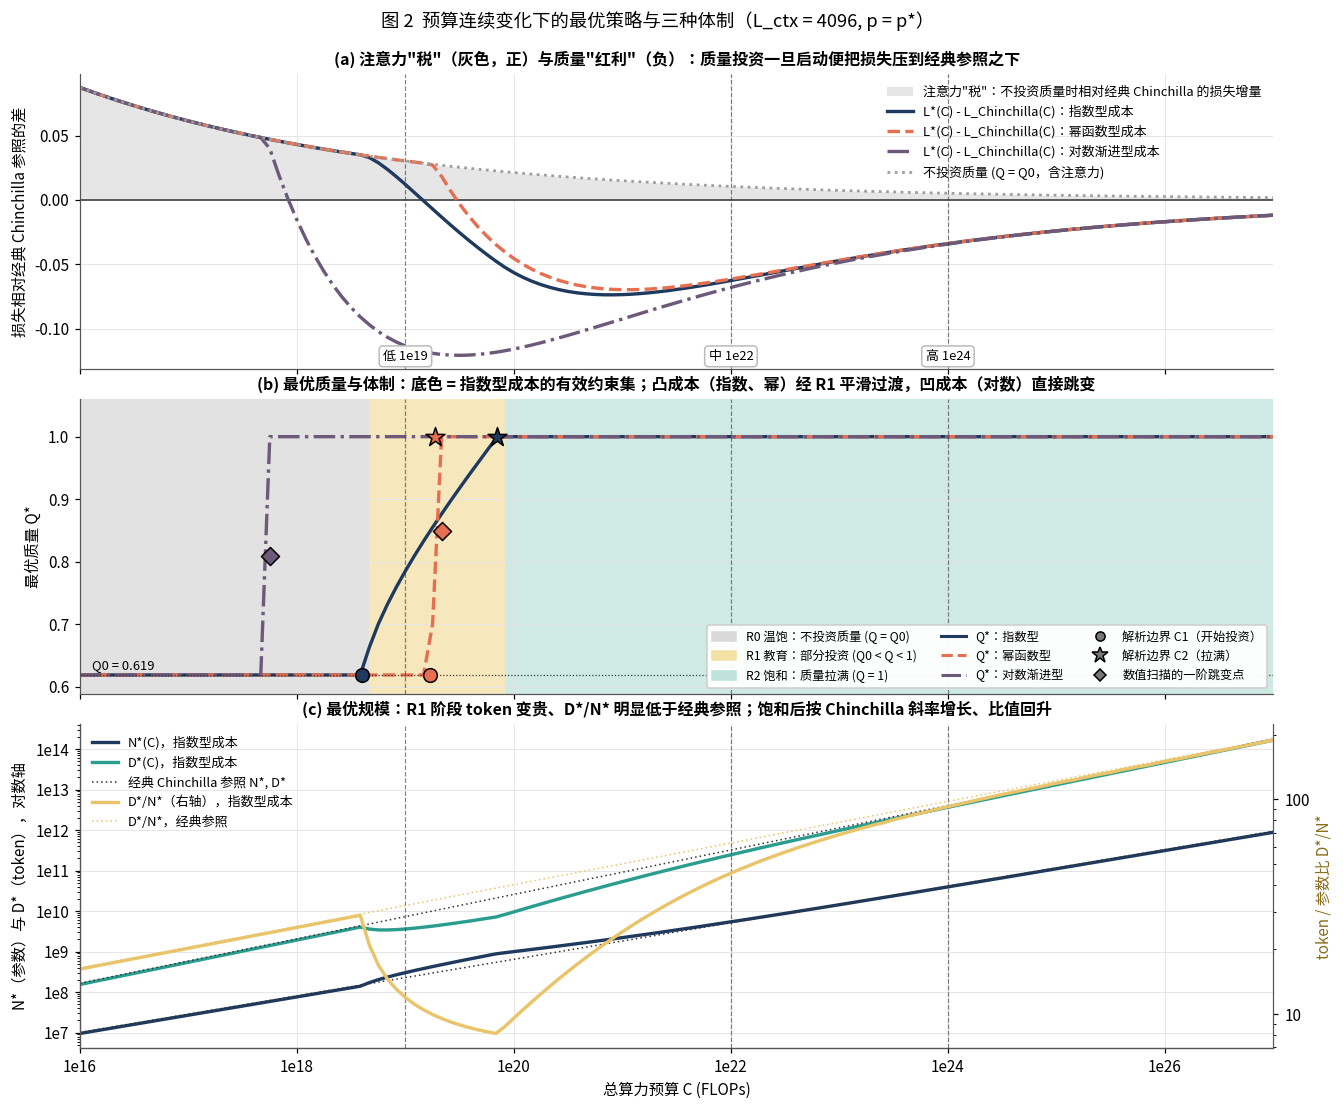

In [5]:
# ============ 4. 预算扫描与结构性转移识别 ============
C_GRID = np.logspace(16, 27, 133)
t0 = time.time(); curves = {}
for cost in COSTS:
    curves[cost] = pd.DataFrame([solve_alloc(C, L_DEFAULT, cost) for C in C_GRID])
    cv = curves[cost]; cv['loss_noQ'] = [solve_noQ(C, L_DEFAULT)['loss'] for C in C_GRID]; cv['M_equiv'] = [equiv_multiplier(C, L_DEFAULT, l) for C, l in zip(C_GRID, cv['loss'])]
    lnC = np.log(C_GRID); dQ = np.gradient(cv['Q'].values, lnC); cv['dQ_dlnC'] = dQ; cv['K_kink'] = np.abs(np.gradient(dQ, lnC)); cv['J_jump'] = np.abs(np.diff(cv['Q'].values, prepend=cv['Q'].values[0]))
print('预算扫描耗时 %.0fs' % (time.time() - t0))

TR = []
for cost in COSTS:
    tb = transition_budgets(L_DEFAULT, cost); cv = curves[cost]
    reg = cv['regime'].values; ch = [(C_GRID[i], reg[i - 1], reg[i]) for i in range(1, len(reg)) if reg[i] != reg[i - 1]]
    jmax = cv['J_jump'].max(); kpk = C_GRID[np.argsort(cv['K_kink'].values)[-2:]]
    TR.append({'成本函数': cost, '解析 C1 (R0->R1)': tb['C1'], '解析 C2 (R1->R2)': tb['C2'], '数值扫描的体制切换': '; '.join('%s->%s @ %.2e' % (a, b, c) for c, a, b in ch), '最大跳跃 |dQ*| (一阶转移指标)': jmax, '拐点统计量峰值位置': ', '.join('%.1e' % v for v in sorted(kpk))})
TRT = pd.DataFrame(TR); print('结构性转移点（默认 L_ctx = %d）:' % L_DEFAULT); display(TRT.assign(**{'解析 C1 (R0->R1)': TRT['解析 C1 (R0->R1)'].map(lambda v: '%.2e' % v), '解析 C2 (R1->R2)': TRT['解析 C2 (R1->R2)'].map(lambda v: '%.2e' % v)})); TRT.to_csv(TAB / 'structural_transition_points.csv', index=False, encoding='utf-8-sig')
for cost in COSTS: curves[cost].to_csv(TAB / ('budget_scan_%s.csv' % {'指数型': 'exp', '幂函数型': 'power', '对数渐进型': 'log'}[cost]), index=False, encoding='utf-8-sig')

# ---- 图 2：体制图（默认 L_ctx）：损失相对经典参照的差、Q*(C) 与体制带、N*/D* 与 D/N ----
L_cls = np.array([solve_noQ(C, 0.0)['loss'] for C in C_GRID]); N_cls = np.array([solve_noQ(C, 0.0)['N'] for C in C_GRID]); D_cls = np.array([solve_noQ(C, 0.0)['D'] for C in C_GRID])
fig = plt.figure(figsize=(14, 11.5)); gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1.1], hspace=0.1)
ax0 = fig.add_subplot(gs[0]); ax1 = fig.add_subplot(gs[1], sharex=ax0); ax2 = fig.add_subplot(gs[2], sharex=ax0)
cvx = curves['指数型']
ax0.axhline(0, color='#333333', lw=1); ax0.fill_between(C_GRID, 0, cvx['loss_noQ'] - L_cls, color=C_GREY, alpha=0.25, lw=0, label='注意力"税"：不投资质量时相对经典 Chinchilla 的损失增量')
for cost in COSTS:
    cv = curves[cost]; ax0.plot(C_GRID, cv['loss'] - L_cls, color=COL_COST[cost], ls=LS_COST[cost], lw=2.2, label='L*(C) - L_Chinchilla(C)：%s成本' % cost)
ax0.plot(C_GRID, cvx['loss_noQ'] - L_cls, color=C_GREY, lw=1.8, ls=':', label='不投资质量 (Q = Q0，含注意力)')
ax0.set_ylabel('损失相对经典 Chinchilla 参照的差'); ax0.legend(frameon=False, fontsize=8.5, loc='upper right'); ax0.tick_params(labelbottom=False)
ax0.set_title('(a) 注意力"税"（灰色，正）与质量"红利"（负）：质量投资一旦启动便把损失压到经典参照之下', fontsize=10.5)
# (b) Q*(C) 与体制带（按指数型成本着色）+ 解析边界标记 + 数值跳变点
reg = cvx['regime'].values; start = 0
for i in range(1, len(reg) + 1):
    if i == len(reg) or reg[i] != reg[start]:
        ax1.axvspan(C_GRID[start], C_GRID[min(i, len(reg) - 1)], color=COL_REG[reg[start]], alpha=0.75, lw=0); start = i
for cost, tb in zip(COSTS, TR):
    cv = curves[cost]; ax1.plot(C_GRID, cv['Q'], color=COL_COST[cost], ls=LS_COST[cost], lw=2.2, label='Q*(C)：%s成本' % cost)
    c1, c2 = tb['解析 C1 (R0->R1)'], tb['解析 C2 (R1->R2)']
    if c1 < c2:                                                     # 凸成本：R1 窗口存在，标出解析边界
        ax1.scatter([c1], [Q0], marker='o', s=80, color=COL_COST[cost], edgecolor='black', zorder=6); ax1.scatter([c2], [1.0], marker='*', s=170, color=COL_COST[cost], edgecolor='black', zorder=6)
    jumps = cv.index[cv['J_jump'] > 0.1].tolist()
    for j_ in jumps: ax1.scatter([C_GRID[j_]], [0.5 * (cv['Q'].iloc[j_ - 1] + cv['Q'].iloc[j_])], marker='D', s=70, color=COL_COST[cost], edgecolor='black', zorder=6)
ax1.axhline(Q0, color='#333333', lw=0.8, ls=':'); ax1.text(C_GRID[0] * 1.3, Q0 + 0.01, 'Q0 = %.3f' % Q0, fontsize=8.5)
ax1.set_ylabel('最优质量 Q*'); ax1.set_ylim(Q0 - 0.03, 1.06); ax1.tick_params(labelbottom=False)
ax1.legend(handles=[Patch(color=COL_REG[k], label=NAME_REG[k]) for k in ('R0', 'R1', 'R2')] + [Line2D([0], [0], color=COL_COST[c], ls=LS_COST[c], lw=2, label='Q*：%s' % c) for c in COSTS] +
                   [Line2D([0], [0], marker='o', ls='', color='#777777', mec='black', label='解析边界 C1（开始投资）'), Line2D([0], [0], marker='*', ls='', color='#777777', mec='black', ms=11, label='解析边界 C2（拉满）'), Line2D([0], [0], marker='D', ls='', color='#777777', mec='black', label='数值扫描的一阶跳变点')],
           frameon=True, fontsize=8, loc='lower right', ncol=3, facecolor='white', framealpha=0.95)
ax1.set_title('(b) 最优质量与体制：底色 = 指数型成本的有效约束集；凸成本（指数、幂）经 R1 平滑过渡，凹成本（对数）直接跳变', fontsize=10.5)
# (c) N*, D*, D/N（指数型成本）与经典参照
cv = cvx
ax2.plot(C_GRID, cv['N'], color=C_NAVY, lw=2.2, label='N*(C)，指数型成本'); ax2.plot(C_GRID, cv['D'], color=C_TEAL, lw=2.2, label='D*(C)，指数型成本')
ax2.plot(C_GRID, N_cls, color='#333333', lw=1, ls=(0, (1, 2)), label='经典 Chinchilla 参照 N*, D*'); ax2.plot(C_GRID, D_cls, color='#333333', lw=1, ls=(0, (1, 2)))
ax2.set_yscale('log'); ax2.yaxis.set_major_formatter(pow10); ax2.set_ylabel('N*（参数）与 D*（token），对数轴')
ax2b = ax2.twinx(); ax2b.grid(False); ax2b.spines['right'].set_visible(True)
ax2b.plot(C_GRID, cv['D_over_N'], color=C_GOLD, lw=2.2, label='D*/N*（右轴），指数型成本'); ax2b.plot(C_GRID, D_cls / N_cls, color=C_GOLD, lw=1, ls=(0, (1, 2)), label='D*/N*，经典参照')
ax2b.set_yscale('log'); ax2b.yaxis.set_major_formatter(plain); ax2b.set_ylabel('token / 参数比 D*/N*', color='#8A6D1A')
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax2b.get_legend_handles_labels(); ax2.legend(h1 + h2, l1 + l2, frameon=False, fontsize=8.5, loc='upper left')
ax2.set_xscale('log'); ax2.xaxis.set_major_formatter(pow10); ax2.set_xlabel('总算力预算 C (FLOPs)'); ax2.set_xlim(C_GRID[0], C_GRID[-1])
for C in BUDGETS:
    for a_ in (ax0, ax1, ax2): a_.axvline(C, color='#333333', lw=0.8, ls='--', alpha=0.6)
    ax0.text(C, ax0.get_ylim()[0] + 0.02 * (ax0.get_ylim()[1] - ax0.get_ylim()[0]), BUD_LAB[C], ha='center', va='bottom', fontsize=8.5, bbox=dict(boxstyle='round', fc='white', ec='#BBBBBB'))
ax2.set_title('(c) 最优规模：R1 阶段 token 变贵、D*/N* 明显低于经典参照；饱和后按 Chinchilla 斜率增长、比值回升', fontsize=10.5)
fig.suptitle('图 2  预算连续变化下的最优策略与三种体制（L_ctx = %d, p = p*）' % L_DEFAULT, fontsize=12, y=0.93)
savefig('fig02_regime_diagram.png'); plt.show()

## 5. 相位图：预算 × 上下文长度的体制划分与转移识别统计量

把解析边界 $C_1^\dagger(L_{ctx}),C_2^\dagger(L_{ctx})$ 作为 $L_{ctx}$ 的函数画在 $(C,L_{ctx})$ 平面上，就得到资源配置的 **相位图**：横向跨越量级是"收入增长"引起的转移，纵向跨越 $L^{crit}$ 是"注意力主导"的外生分界。相位图用数值扫描（网格上逐点全局最优）着色，用解析边界画线，两者应当吻合。右图给出默认 $L_{ctx}$ 下的识别统计量 $J(C)$、$K(C)$。

相位图计算耗时 9s


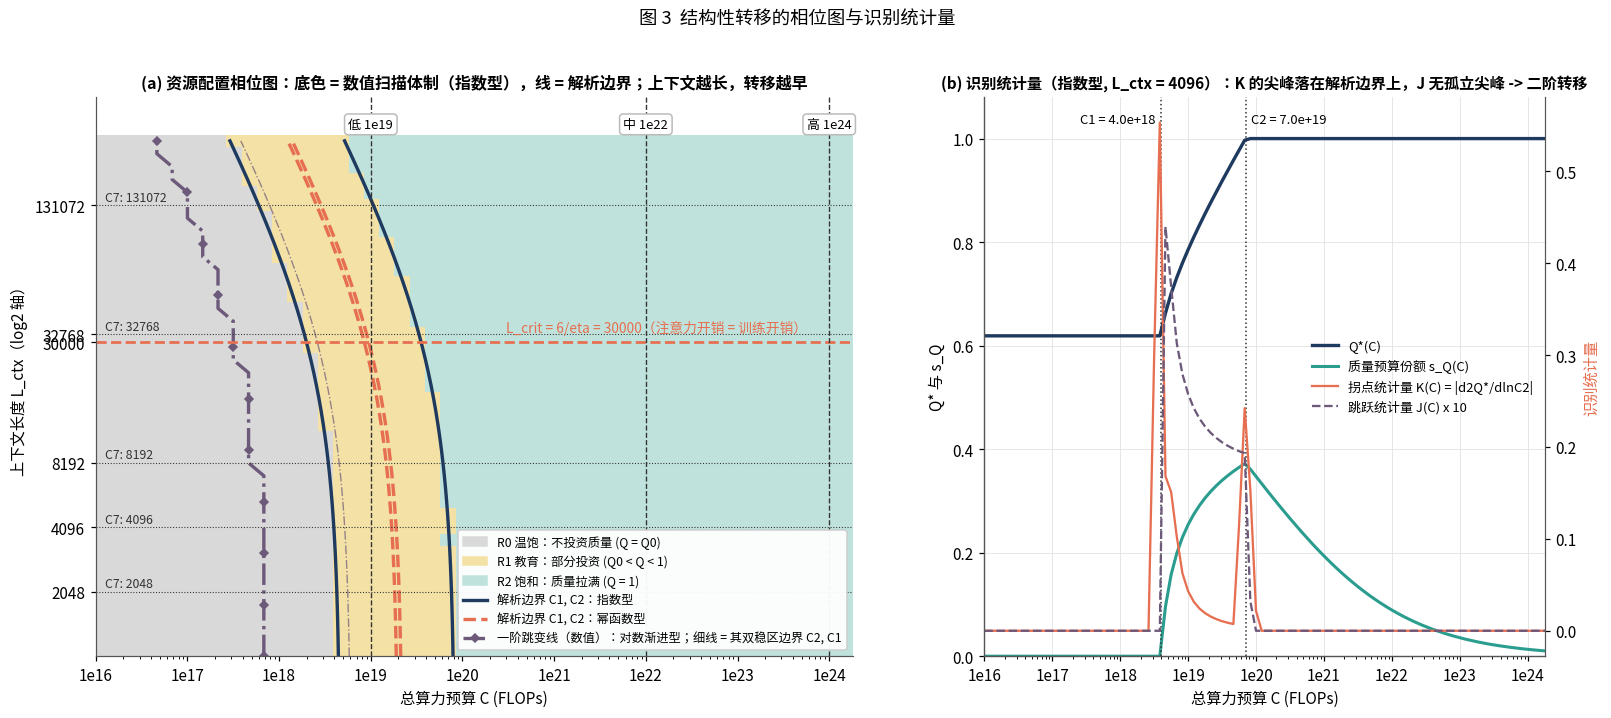

In [6]:
# ============ 5. 相位图 ============
t0 = time.time(); Cg = np.logspace(16, 27, 67); Lg = np.logspace(np.log10(1024), np.log10(262144), 41)
PH = {cost: np.zeros((len(Lg), len(Cg)), dtype=int) for cost in COSTS}; QS = {cost: np.zeros((len(Lg), len(Cg))) for cost in COSTS}
for cost in COSTS:
    for i, L_ in enumerate(Lg):
        for j, C in enumerate(Cg):
            s = solve_alloc(C, L_, cost, refine=False); PH[cost][i, j] = {'R0': 0, 'R1': 1, 'R2': 2}[s['regime']]; QS[cost][i, j] = s['Q']
BND = {cost: pd.DataFrame([{'L_ctx': L_, **transition_budgets(L_, cost)} for L_ in Lg]) for cost in COSTS}
print('相位图计算耗时 %.0fs' % (time.time() - t0))
for cost in COSTS: BND[cost].to_csv(TAB / ('phase_boundaries_%s.csv' % {'指数型': 'exp', '幂函数型': 'power', '对数渐进型': 'log'}[cost]), index=False, encoding='utf-8-sig')

fig = plt.figure(figsize=(17, 6.6)); gs = gridspec.GridSpec(1, 2, width_ratios=[1.35, 1], wspace=0.2)
ax = fig.add_subplot(gs[0]); cmap_reg = mpl.colors.ListedColormap([COL_REG['R0'], COL_REG['R1'], COL_REG['R2']])
ax.pcolormesh(Cg, Lg, PH['指数型'], cmap=cmap_reg, vmin=-0.5, vmax=2.5, shading='nearest'); ax.grid(False)
JUMP = {}                                                          # 凹成本（对数）的一阶跳变线：数值扫描中体制首次到达 R2 的预算
for cost in COSTS:
    b = BND[cost]; convex = bool((b['C1'] < b['C2']).mean() > 0.5)
    if convex:
        ax.plot(b['C1'], b['L_ctx'], color=COL_COST[cost], ls=LS_COST[cost], lw=2.2); ax.plot(b['C2'], b['L_ctx'], color=COL_COST[cost], ls=LS_COST[cost], lw=2.2)
    else:
        ax.plot(b['C2'], b['L_ctx'], color=COL_COST[cost], ls=LS_COST[cost], lw=0.9, alpha=0.7); ax.plot(b['C1'], b['L_ctx'], color=COL_COST[cost], ls=LS_COST[cost], lw=0.9, alpha=0.7)
        jc = [Cg[np.argmax(PH[cost][i] == 2)] if (PH[cost][i] == 2).any() else np.nan for i in range(len(Lg))]; JUMP[cost] = np.array(jc)
        ax.plot(jc, Lg, color=COL_COST[cost], ls=LS_COST[cost], lw=2.2, marker='D', ms=3.5, markevery=4)
ax.axhline(L_CRIT, color=C_CORAL, lw=1.8, ls='--'); ax.text(3e20, L_CRIT * 1.12, 'L_crit = 6/eta = %d（注意力开销 = 训练开销）' % L_CRIT, color=C_CORAL, fontsize=9)
for L_ in FEAS: ax.axhline(L_, color='#333333', lw=0.7, ls=':'); ax.text(Cg[0] * 1.25, L_ * 1.05, 'C7: %d' % L_, ha='left', fontsize=8, color='#333333')
for C in BUDGETS: ax.axvline(C, color='#333333', lw=0.9, ls='--'); ax.text(C, Lg[-1] * 1.15, BUD_LAB[C], ha='center', fontsize=8.5, bbox=dict(boxstyle='round', fc='white', ec='#BBBBBB'))
ax.set_xscale('log'); ax.set_yscale('log', base=2); ax.xaxis.set_major_formatter(pow10); ax.set_yticks(FEAS + [int(L_CRIT)]); ax.set_yticklabels(['%d' % v for v in FEAS] + ['30000']); ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlim(Cg[0], 1e24 * 1.8); ax.set_ylim(Lg[0], Lg[-1] * 1.6); ax.set_xlabel('总算力预算 C (FLOPs)'); ax.set_ylabel('上下文长度 L_ctx（log2 轴）')
ax.legend(handles=[Patch(color=COL_REG[k], label=NAME_REG[k]) for k in ('R0', 'R1', 'R2')] + [Line2D([0], [0], color=COL_COST[c], ls=LS_COST[c], lw=2.2, label='解析边界 C1, C2：%s' % c) for c in COSTS if c in ('指数型', '幂函数型')] +
                   [Line2D([0], [0], color=COL_COST['对数渐进型'], ls=LS_COST['对数渐进型'], lw=2.2, marker='D', ms=4, label='一阶跳变线（数值）：对数渐进型；细线 = 其双稳区边界 C2, C1')], loc='lower right', frameon=True, fontsize=8, facecolor='white', framealpha=0.95)
ax.set_title('(a) 资源配置相位图：底色 = 数值扫描体制（指数型），线 = 解析边界；上下文越长，转移越早', fontsize=10.5)
ax = fig.add_subplot(gs[1]); cv = curves['指数型']
ax.plot(C_GRID, cv['Q'], color=C_NAVY, lw=2.2, label='Q*(C)'); ax.plot(C_GRID, cv['s_Q'], color=C_TEAL, lw=2, label='质量预算份额 s_Q(C)'); ax.set_ylabel('Q* 与 s_Q'); ax.set_ylim(0, 1.08)
axr = ax.twinx(); axr.grid(False); axr.spines['right'].set_visible(True)
axr.plot(C_GRID, cv['K_kink'], color=C_CORAL, lw=1.5, ls='-', label='拐点统计量 K(C) = |d2Q*/dlnC2|'); axr.plot(C_GRID, cv['J_jump'] * 10, color=C_PLUM, lw=1.5, ls='--', label='跳跃统计量 J(C) x 10')
axr.set_ylabel('识别统计量', color=C_CORAL)
tb = TR[0]
for key, lab_, ha_ in (('解析 C1 (R0->R1)', 'C1', 'right'), ('解析 C2 (R1->R2)', 'C2', 'left')):
    v = tb[key]
    if np.isfinite(v): ax.axvline(v, color='#333333', lw=1, ls=':'); ax.text(v * (0.85 if ha_ == 'right' else 1.18), 1.03, '%s = %.1e' % (lab_, v), ha=ha_, fontsize=8.5)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10); ax.set_xlabel('总算力预算 C (FLOPs)'); ax.set_xlim(C_GRID[0], 1e24 * 1.8)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = axr.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=8.5, loc='center right')
ax.set_title('(b) 识别统计量（指数型, L_ctx = %d）：K 的尖峰落在解析边界上，J 无孤立尖峰 -> 二阶转移' % L_DEFAULT, fontsize=10)
fig.suptitle('图 3  结构性转移的相位图与识别统计量', fontsize=12, y=1.0)
savefig('fig03_phase_diagram.png'); plt.show()

## 6. 预算份额的三元轨迹与 $L_{ctx}$ 敏感性

份额 $(s_{train},s_{attn},s_Q)$ 之和为 1，天然落在三元图（单纯形）上。随着 $C$ 从 $10^{16}$ 增到 $10^{27}$，每个 $L_{ctx}$ 对应一条轨迹：从"训练"顶点出发，经过"质量"方向的凸起（R1 体制），再回到训练–注意力边上（R2 体制，质量份额趋于 0）；$L_{ctx}$ 决定轨迹终点在训练–注意力边上的位置（$s_{attn}/s_{train}=\eta L_{ctx}/6$）。随后在 C7 的 5 个可行值与 $L^{crit}$ 上做敏感性分析：平行坐标图并列三档预算下的最优配置。

三元轨迹计算耗时 1s
L_ctx 敏感性（指数型成本）:


,L_ctx,相对 L_crit,预算,有效训练预算系数 1/(1+eta L/6),N* (B),D* (B),D*/N*,Q*,L*,s_train,s_attn,s_Q,体制,相对 L_ctx=2048 的损失增量,等效算力倍数 M
0,2048,<,1e+19,0.9361,0.3069,3.8376,12.5059,0.7755,3.2125,0.7066,0.0482,0.2452,R1,0.0000,1.0699
1,2048,<,1e+22,0.9361,5.5991,253.0856,45.2011,1.0000,2.1505,0.8502,0.0580,0.0917,R2,0.0000,2.5817
2,2048,<,1e+24,0.9361,40.7372,3777.3801,92.7255,1.0000,1.9139,0.9233,0.0630,0.0137,R2,0.0000,2.8240
3,4096,<,1e+19,0.8799,0.3026,3.6151,11.9488,0.7854,3.2248,0.6563,0.0896,0.2541,R1,0.0123,1.0802
4,4096,<,1e+22,0.8799,5.4273,246.0979,45.3444,1.0000,2.1546,0.8014,0.1094,0.0892,R2,0.0042,2.5900
5,4096,<,1e+24,0.8799,39.5586,3657.8846,92.4676,1.0000,1.9160,0.8682,0.1185,0.0133,R2,0.0021,2.8253
6,8192,<,1e+19,0.7855,0.2942,3.2535,11.0591,0.8029,3.2474,0.5743,0.1568,0.2689,R1,0.0348,1.1003
7,8192,<,1e+22,0.7855,5.1285,233.6552,45.5598,1.0000,2.1624,0.7190,0.1963,0.0847,R2,0.0119,2.6047
8,8192,<,1e+24,0.7855,37.5489,3443.0818,91.6961,1.0000,1.9200,0.7757,0.2118,0.0125,R2,0.0061,2.8276
9,32768,>,1e+19,0.4780,0.2543,2.1406,8.4180,0.8736,3.3471,0.3266,0.3567,0.3167,R1,0.1345,1.2071


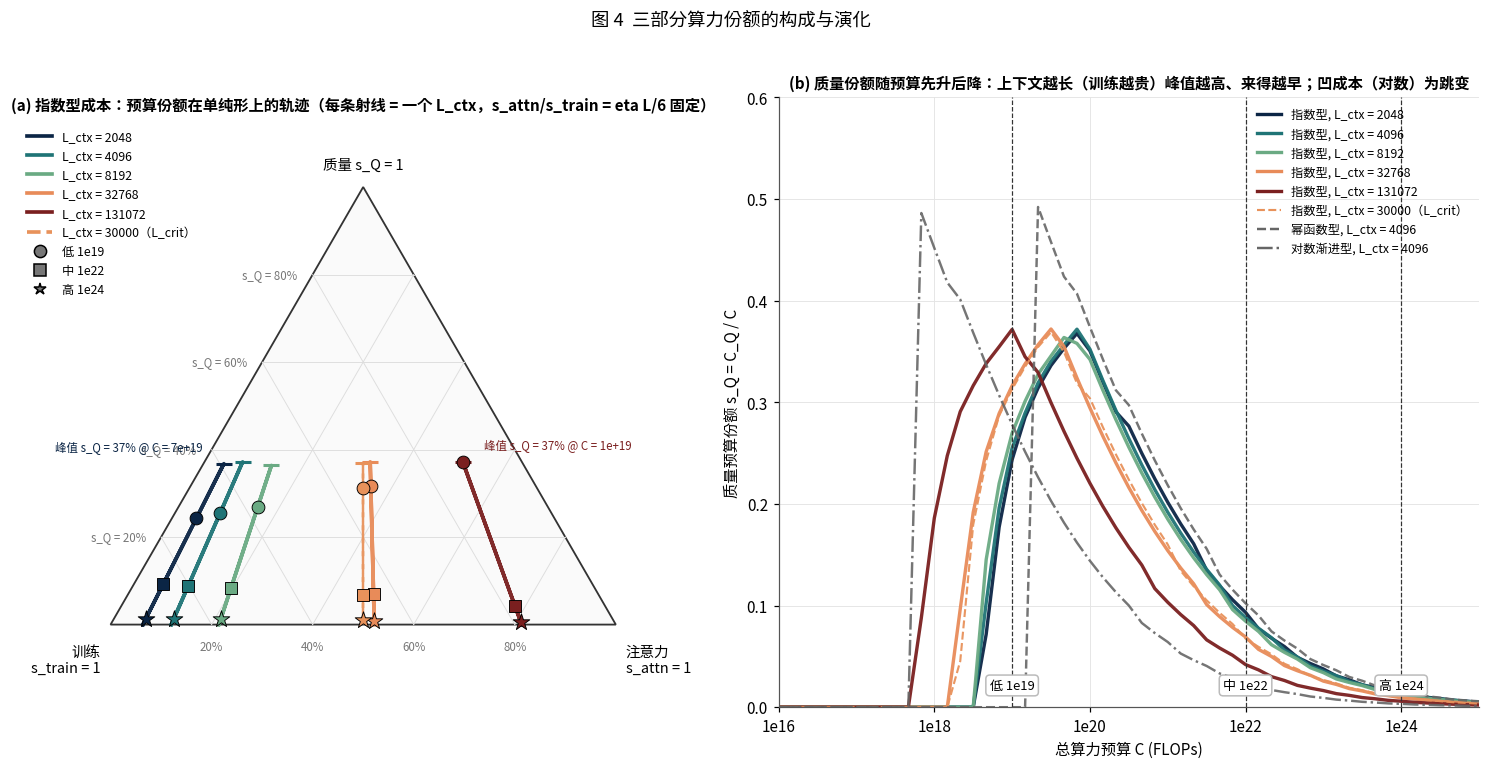

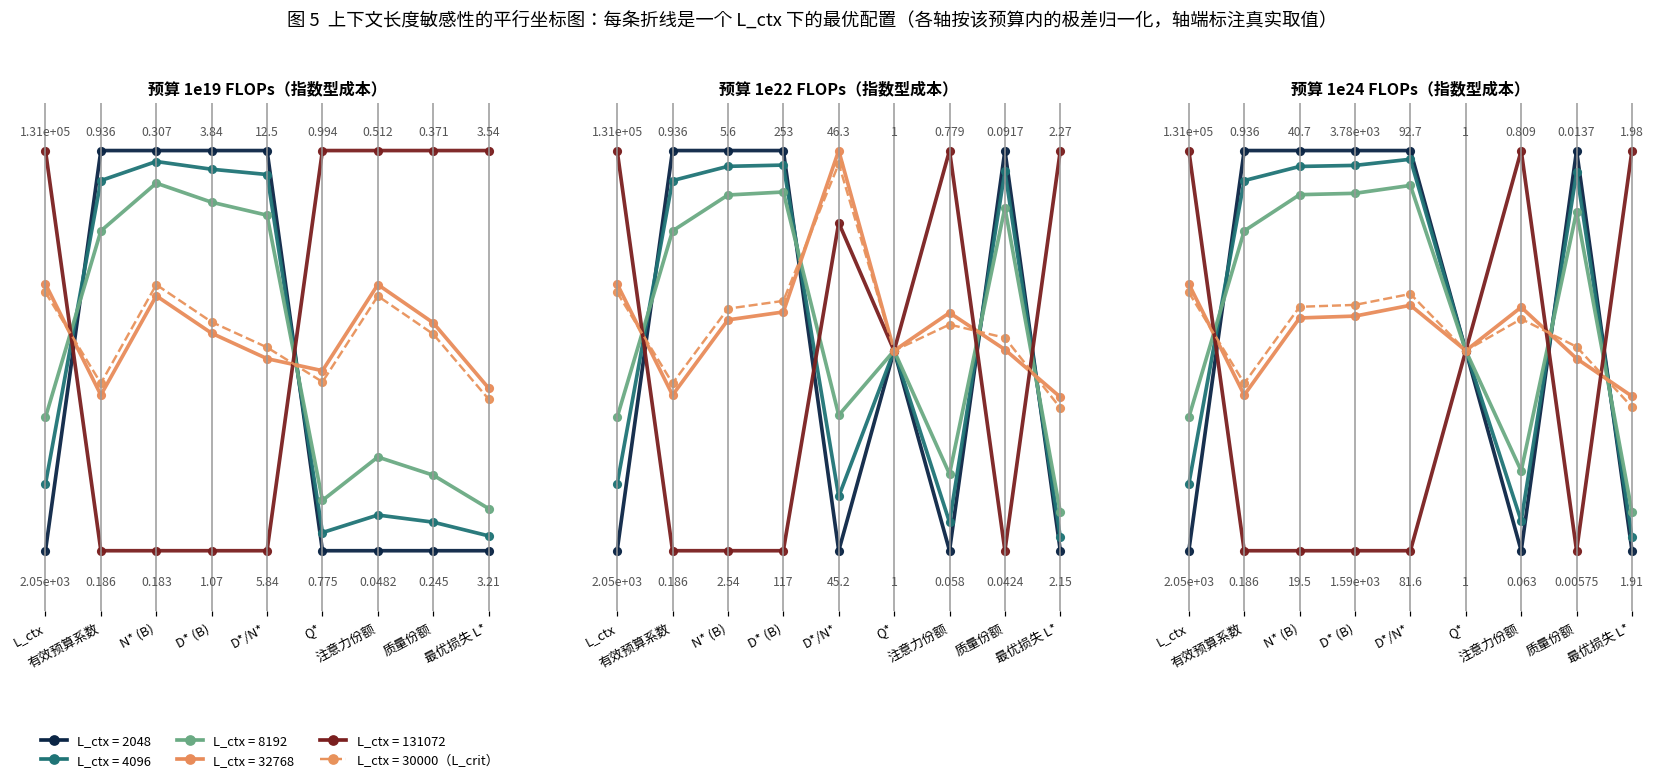

In [7]:
# ============ 6. 三元轨迹 + L_ctx 敏感性 ============
def tern_xy(a, b, c):
    a, b, c = (np.asarray(v, float) for v in (a, b, c)); t = a + b + c; return 0.5 * (2 * b + c) / t, (np.sqrt(3) / 2) * c / t
normL = mpl.colors.LogNorm(vmin=min(L_ALL), vmax=max(L_ALL)); COL_L = {L_: CMAP_L(normL(L_)) for L_ in L_ALL}
t0 = time.time(); TRAJ = {(cost, L_): pd.DataFrame([solve_alloc(C, L_, cost, refine=False) for C in C_GRID[::2]]) for cost in COSTS for L_ in L_ALL}
print('三元轨迹计算耗时 %.0fs' % (time.time() - t0))
fig = plt.figure(figsize=(17, 7.2)); gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.05], wspace=0.12)
ax = fig.add_subplot(gs[0]); ax.axis('off'); ax.set_aspect('equal'); cost = '指数型'
ax.add_patch(Polygon([[0, 0], [1, 0], [0.5, np.sqrt(3) / 2]], closed=True, fc='#FAFAFA', ec='#333333', lw=1.2))
for f_ in (0.2, 0.4, 0.6, 0.8):
    for (p1, p2) in (((f_, 1 - f_, 0), (f_, 0, 1 - f_)), ((1 - f_, f_, 0), (0, f_, 1 - f_)), ((1 - f_, 0, f_), (0, 1 - f_, f_))):
        x1, y1 = tern_xy(*p1); x2, y2 = tern_xy(*p2); ax.plot([x1, x2], [y1, y2], color='#DDDDDD', lw=0.6, zorder=1)
ax.text(-0.02, -0.04, '训练\ns_train = 1', ha='right', va='top', fontsize=9.5); ax.text(1.02, -0.04, '注意力\ns_attn = 1', ha='left', va='top', fontsize=9.5); ax.text(0.5, np.sqrt(3) / 2 + 0.03, '质量 s_Q = 1', ha='center', va='bottom', fontsize=9.5)
for f_ in (0.2, 0.4, 0.6, 0.8):
    x_, y_ = tern_xy(1 - f_, 0, f_); ax.text(x_ - 0.03, y_, 's_Q = %.0f%%' % (100 * f_), ha='right', va='center', fontsize=7.5, color='#777777')
    x_, y_ = tern_xy(1 - f_, f_, 0); ax.text(x_, -0.03, '%.0f%%' % (100 * f_), ha='center', va='top', fontsize=7.5, color='#777777')
for L_ in L_ALL:
    tr = TRAJ[(cost, L_)]; x_, y_ = tern_xy(tr['s_train'], tr['s_attn'], tr['s_Q']); ls = '--' if L_ == int(L_CRIT) else '-'
    ax.plot(x_, y_, color=COL_L[L_], lw=2.4 if ls == '-' else 1.6, ls=ls, alpha=0.95, zorder=3)
    k_ = int(np.argmax(tr['s_Q'].values)); ax.scatter([x_[k_]], [y_[k_]], marker='_', s=120, color=COL_L[L_], linewidths=2, zorder=4)
    if L_ in (FEAS[0], FEAS[-1]): ax.annotate('峰值 s_Q = %.0f%% @ C = %.0e' % (100 * tr['s_Q'].iloc[k_], tr['C'].iloc[k_]), (x_[k_], y_[k_]), xytext=(-14 if L_ == FEAS[0] else 14, 8), textcoords='offset points', ha='right' if L_ == FEAS[0] else 'left', fontsize=7.5, color=COL_L[L_])
    for C, mk in zip(BUDGETS, ('o', 's', '*')):
        s_ = solve_alloc(C, L_, cost, refine=False); xx, yy = tern_xy(s_['s_train'], s_['s_attn'], s_['s_Q']); ax.scatter([xx], [yy], marker=mk, s=70 if mk != '*' else 130, color=COL_L[L_], edgecolor='black', linewidths=0.6, zorder=5)
ax.set_xlim(-0.16, 1.16); ax.set_ylim(-0.12, 1.0)
ax.legend(handles=[Line2D([0], [0], color=COL_L[L_], lw=2.4, ls='--' if L_ == int(L_CRIT) else '-', label='L_ctx = %d%s' % (L_, '（L_crit）' if L_ == int(L_CRIT) else '')) for L_ in L_ALL] + [Line2D([0], [0], marker=m, ls='', color='#777777', mec='black', ms=8, label=BUD_LAB[C]) for C, m in zip(BUDGETS, ('o', 's', '*'))], loc='upper left', bbox_to_anchor=(-0.02, 1.0), frameon=False, fontsize=8)
ax.set_title('(a) 指数型成本：预算份额在单纯形上的轨迹（每条射线 = 一个 L_ctx，s_attn/s_train = eta L/6 固定）', fontsize=10)
ax = fig.add_subplot(gs[1])
for L_ in L_ALL:
    tr = TRAJ[('指数型', L_)]; ax.plot(tr['C'], tr['s_Q'], color=COL_L[L_], ls='-' if L_ != int(L_CRIT) else '--', lw=2.2 if L_ != int(L_CRIT) else 1.4, alpha=0.95)
for cost_ in ('幂函数型', '对数渐进型'):
    tr = TRAJ[(cost_, L_DEFAULT)]; ax.plot(tr['C'], tr['s_Q'], color='#666666', ls=LS_COST[cost_], lw=1.6, alpha=0.9)
for C in BUDGETS: ax.axvline(C, color='#333333', lw=0.8, ls='--'); ax.text(C, 0.015, BUD_LAB[C], ha='center', va='bottom', fontsize=8.5, bbox=dict(boxstyle='round', fc='white', ec='#BBBBBB'))
ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10); ax.set_xlim(1e16, 1e25); ax.set_ylim(0, 0.6); ax.set_xlabel('总算力预算 C (FLOPs)'); ax.set_ylabel('质量预算份额 s_Q = C_Q / C')
ax.legend(handles=[Line2D([0], [0], color=COL_L[L_], lw=2.2 if L_ != int(L_CRIT) else 1.4, ls='-' if L_ != int(L_CRIT) else '--', label='指数型, L_ctx = %d%s' % (L_, '（L_crit）' if L_ == int(L_CRIT) else '')) for L_ in L_ALL] + [Line2D([0], [0], color='#666666', ls=LS_COST[c], lw=1.6, label='%s, L_ctx = %d' % (c, L_DEFAULT)) for c in ('幂函数型', '对数渐进型')], frameon=False, fontsize=8, loc='upper right')
ax.set_title('(b) 质量份额随预算先升后降：上下文越长（训练越贵）峰值越高、来得越早；凹成本（对数）为跳变', fontsize=10)
fig.suptitle('图 4  三部分算力份额的构成与演化', fontsize=12, y=0.99)
savefig('fig04_ternary_budget_shares.png'); plt.show()

# ---- L_ctx 敏感性表 ----
rows = []
for L_ in L_ALL:
    for C in BUDGETS:
        s = solve_alloc(C, L_, '指数型'); ref = solve_alloc(C, FEAS[0], '指数型')
        rows.append({'L_ctx': L_, '相对 L_crit': '=' if L_ == int(L_CRIT) else ('<' if L_ < L_CRIT else '>'), '预算': C, '有效训练预算系数 1/(1+eta L/6)': 1 / (1 + ETA * L_ / 6), 'N* (B)': s['N'] / 1e9, 'D* (B)': s['D'] / 1e9, 'D*/N*': s['D_over_N'], 'Q*': s['Q'], 'L*': s['loss'],
                     's_train': s['s_train'], 's_attn': s['s_attn'], 's_Q': s['s_Q'], '体制': s['regime'], '相对 L_ctx=%d 的损失增量' % FEAS[0]: s['loss'] - ref['loss'], '等效算力倍数 M': equiv_multiplier(C, L_, s['loss'])})
SENS_L = pd.DataFrame(rows); SENS_L.to_csv(TAB / 'sensitivity_context_length.csv', index=False, encoding='utf-8-sig')
print('L_ctx 敏感性（指数型成本）:'); display(SENS_L.assign(**{'预算': SENS_L['预算'].map(fmtC)}))

# ---- 图 5：平行坐标图（三档预算） ----
AXES_PC = [('L_ctx', 'L_ctx', True), ('有效训练预算系数 1/(1+eta L/6)', '有效预算系数', False), ('N* (B)', 'N* (B)', True), ('D* (B)', 'D* (B)', True), ('D*/N*', 'D*/N*', True), ('Q*', 'Q*', False), ('s_attn', '注意力份额', False), ('s_Q', '质量份额', False), ('L*', '最优损失 L*', False)]
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, C in zip(axes, BUDGETS):
    sub = SENS_L[SENS_L['预算'] == C].reset_index(drop=True); ax.grid(False)
    lo = []; hi = []
    for col, lab_, islog in AXES_PC:
        v = np.log10(sub[col].values) if islog else sub[col].values; lo.append(v.min()); hi.append(v.max())
    for r_i, r in sub.iterrows():
        ys = []
        for k, (col, lab_, islog) in enumerate(AXES_PC):
            v = np.log10(r[col]) if islog else r[col]; ys.append(0.5 if hi[k] == lo[k] else (v - lo[k]) / (hi[k] - lo[k]))
        ax.plot(range(len(AXES_PC)), ys, color=COL_L[int(r['L_ctx'])], lw=2.4 if r['L_ctx'] != int(L_CRIT) else 1.6, ls='-' if r['L_ctx'] != int(L_CRIT) else '--', marker='o', ms=5, alpha=0.95)
    for k, (col, lab_, islog) in enumerate(AXES_PC):
        ax.axvline(k, color='#999999', lw=1); vmin = 10 ** lo[k] if islog else lo[k]; vmax = 10 ** hi[k] if islog else hi[k]
        ax.text(k, -0.06, ('%.3g' % vmin), ha='center', va='top', fontsize=8, color='#555555'); ax.text(k, 1.03, ('%.3g' % vmax), ha='center', va='bottom', fontsize=8, color='#555555')
    ax.set_xticks(range(len(AXES_PC))); ax.set_xticklabels([a[1] for a in AXES_PC], rotation=28, ha='right', fontsize=8.5); ax.set_yticks([]); ax.set_ylim(-0.15, 1.12); ax.set_xlim(-0.3, len(AXES_PC) - 0.7)
    for sp in ('left', 'top', 'right', 'bottom'): ax.spines[sp].set_visible(False)
    ax.set_title('预算 %s FLOPs（指数型成本）' % BUD_LAB[C].split(' ')[1], fontsize=10.5)
axes[0].legend(handles=[Line2D([0], [0], color=COL_L[L_], lw=2.4 if L_ != int(L_CRIT) else 1.6, ls='-' if L_ != int(L_CRIT) else '--', marker='o', label='L_ctx = %d%s' % (L_, '（L_crit）' if L_ == int(L_CRIT) else '')) for L_ in L_ALL], loc='upper left', bbox_to_anchor=(0.0, -0.22), ncol=3, frameon=False, fontsize=8.5)
fig.suptitle('图 5  上下文长度敏感性的平行坐标图：每条折线是一个 L_ctx 下的最优配置（各轴按该预算内的极差归一化，轴端标注真实取值）', fontsize=12, y=1.02)
savefig('fig05_parallel_coordinates_Lctx.png'); plt.show()

## 7. 参数敏感性（龙卷风图）、成本函数的转移窗口与质量投资的等效算力

问题二给出的参数都有不确定性：$\kappa$ 的 Bootstrap 区间、指数 $(\alpha,\beta)$ 的跨族 5%/95% 情形（已按 B1 重新校准 $E,A,B$）、基线质量 $Q_0$ 随配比的变化、注意力系数 $\eta$ 的取值、以及配比乘子 $\psi_p$。逐一扰动后观察三个决策量：中档预算的最优损失 $L^\star(10^{22})$、低档预算的最优质量 $Q^\star(10^{19})$（内点体制，对参数最敏感）、以及转移边界 $C_2^\dagger$。最后比较三类成本函数的 R1 窗口 $[C_1^\dagger,C_2^\dagger]$ 随 $L_{ctx}$ 的变化，并给出质量投资的等效算力放大倍数 $M(C)$。

基准:  {'L*(1e22)': '2.155', 'Q*(1e19)': '0.7854', 'N*(1e22) B': '5.427', 'C2': '7.033e+19'}
转移窗口 / 跳变点:


,因素,取值,L*(1e22) 低,Q*(1e19) 低,N*(1e22) B 低,C2 低,L*(1e22) 高,Q*(1e19) 高,N*(1e22) B 高,C2 高
0,kappa 95% CI,"[0.446, 0.474]",2.1546,0.7734,5.4273,8e+19,2.1546,0.7979,5.4273,6e+19
1,"指数 (alpha,beta) 5% / 95% 情形","(0.19,0.18) / (0.29,0.29)",2.1222,1.0000,4.9176,3e+18,2.1510,0.7942,6.9326,5e+19
2,指数：真实跨族值 / B1,"(0.28,0.25)",2.1442,0.8411,5.7101,4e+19,2.1546,0.7854,5.4273,7e+19
3,基线质量 Q0 -0.1 / +0.1,0.619 -/+ 0.1,2.1550,0.8188,5.4530,6e+19,2.1540,0.7189,5.3794,8e+19
4,Q0 = 全局均值 / 均匀配比,0.614 / 0.616,2.1547,0.7881,5.4290,7e+19,2.1546,0.7868,5.4283,7e+19
5,注意力系数 eta x0.5 / x2,1e-4 / 4e-4,2.1505,0.7755,5.5991,8e+19,2.1624,0.8029,5.1285,6e+19
6,psi_p：对数线性最优 / 均匀,0.979 / 1.017,2.1446,0.7854,5.4272,7e+19,2.1624,0.7854,5.4272,7e+19


,成本函数,L_ctx,C1,C2,"C_jump(数值, 仅一阶跳变)",类型
0,指数型,2048,4.26e+18,7.58e+19,-,"凸成本：R1 窗口 [C1, C2]"
1,指数型,4096,3.95e+18,7.03e+19,-,"凸成本：R1 窗口 [C1, C2]"
2,指数型,8192,3.44e+18,6.13e+19,-,"凸成本：R1 窗口 [C1, C2]"
3,指数型,32768,1.88e+18,3.35e+19,-,"凸成本：R1 窗口 [C1, C2]"
4,指数型,131072,5.99e+17,1.07e+19,-,"凸成本：R1 窗口 [C1, C2]"
5,指数型,30000,1.99e+18,3.54e+19,-,"凸成本：R1 窗口 [C1, C2]"
6,幂函数型,2048,1.82e+19,2.04e+19,1.78e+19,"凸成本：R1 窗口 [C1, C2]"
7,幂函数型,4096,1.69e+19,1.89e+19,1.78e+19,"凸成本：R1 窗口 [C1, C2]"
8,幂函数型,8192,1.47e+19,1.65e+19,-,"凸成本：R1 窗口 [C1, C2]"
9,幂函数型,32768,8.05e+18,9.00e+18,8.25e+18,"凸成本：R1 窗口 [C1, C2]"


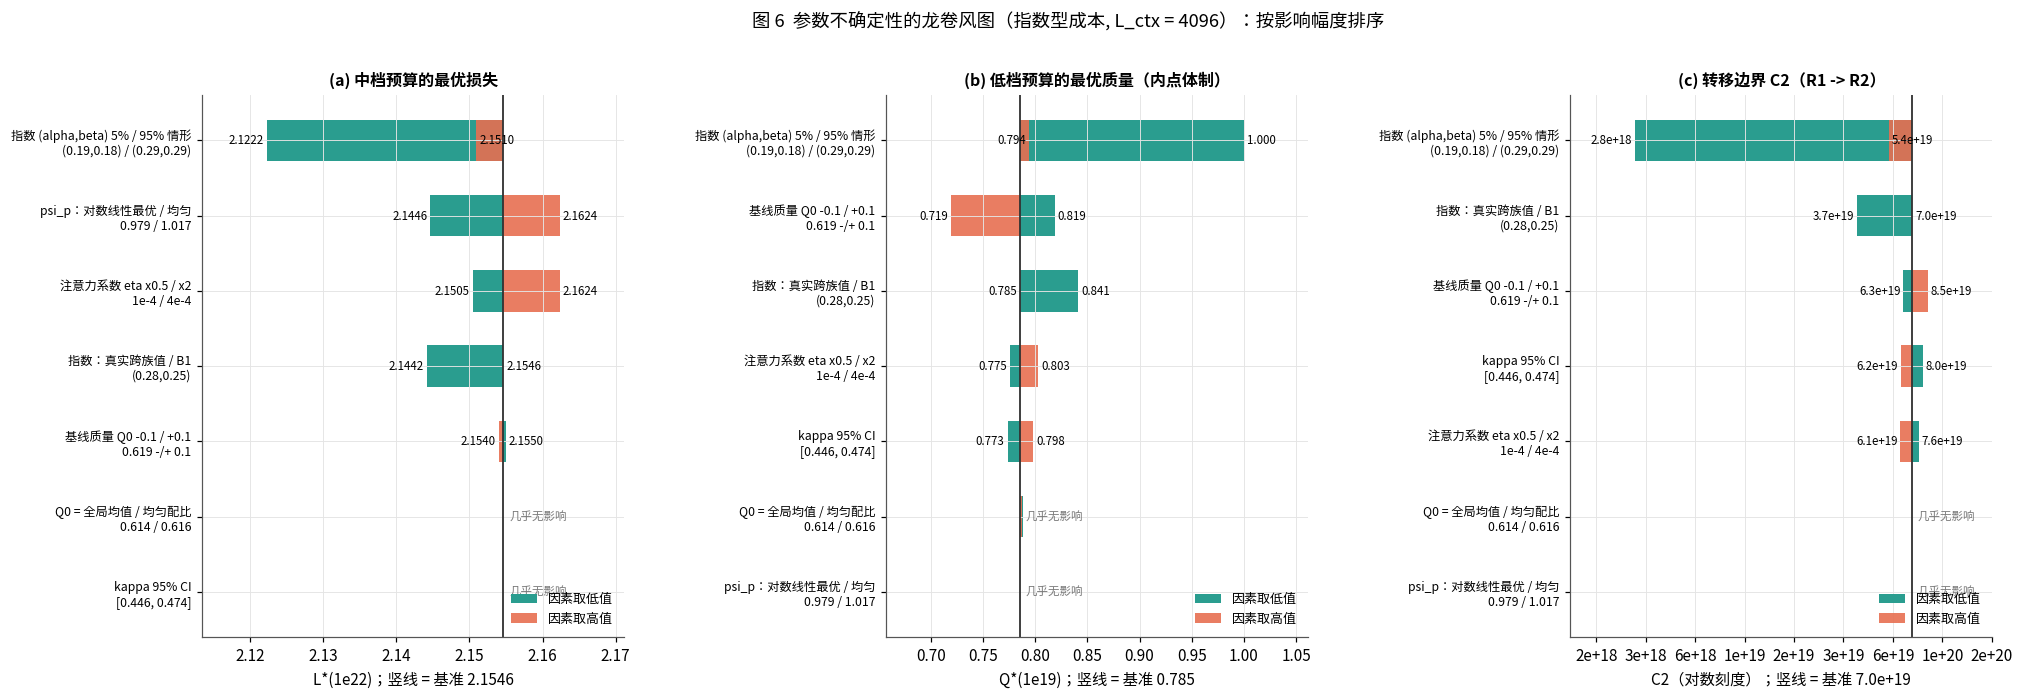

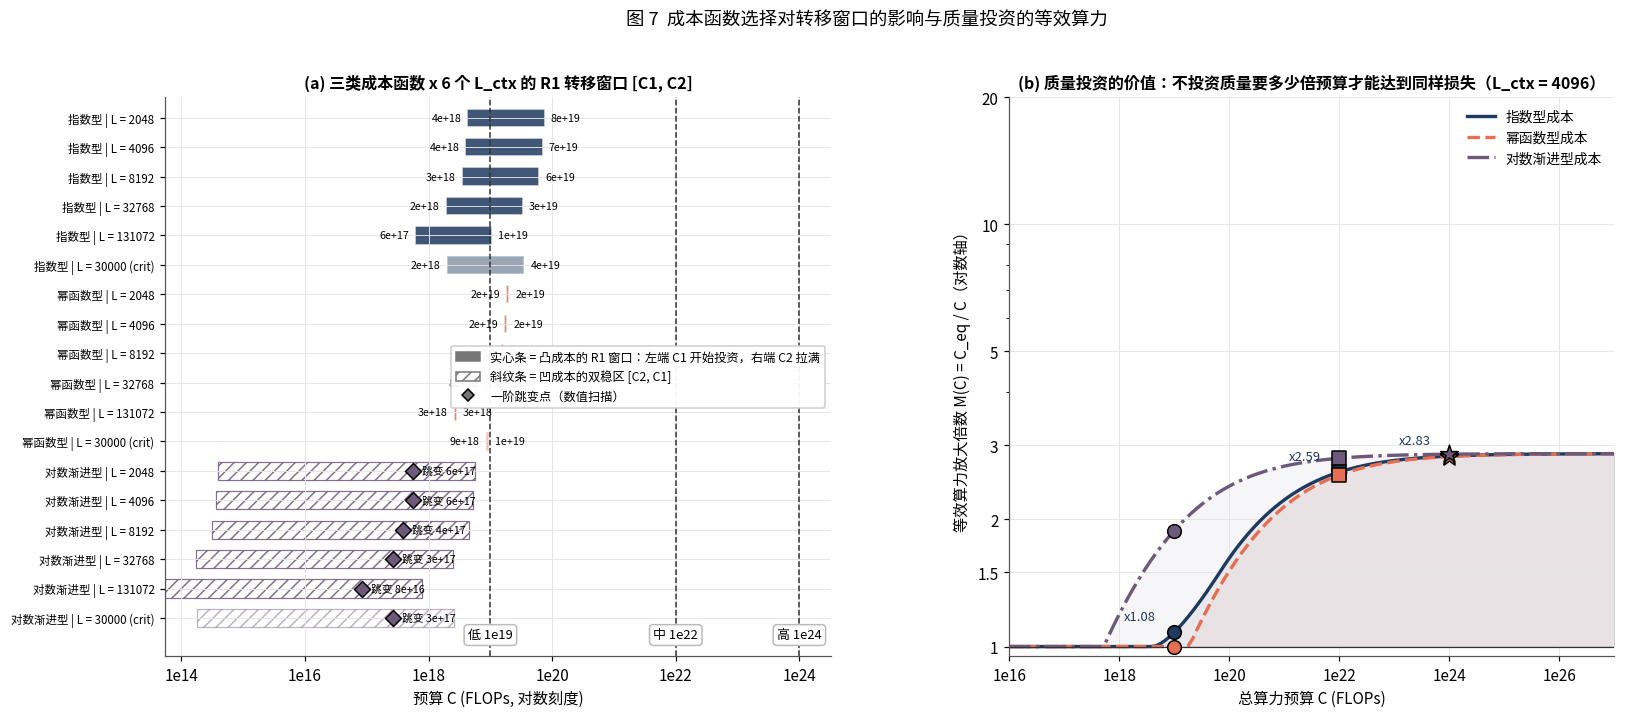

In [8]:
# ============ 7. 龙卷风图 + 转移窗口 + 等效算力 ============
def outputs(**kw):
    s22 = solve_alloc(1e22, L_DEFAULT, '指数型', **kw); s19 = solve_alloc(1e19, L_DEFAULT, '指数型', **kw)
    tb = transition_budgets(L_DEFAULT, '指数型', kw.get('Q0_'), kw.get('th'), kw.get('kappa'), kw.get('eta'))
    return {'L*(1e22)': s22['loss'], 'Q*(1e19)': s19['Q'], 'N*(1e22) B': s22['N'] / 1e9, 'C2': tb['C2']}
base_out = outputs(); scen = []
scen.append(('kappa 95% CI', outputs(kappa=KAPPA_CI[0]), outputs(kappa=KAPPA_CI[1]), '[%.3f, %.3f]' % tuple(KAPPA_CI)))
if 'p5' in EXP_SCEN and 'p95' in EXP_SCEN:
    scen.append(('指数 (alpha,beta) 5% / 95% 情形', outputs(th=EXP_SCEN['p5']), outputs(th=EXP_SCEN['p95']), '(%.2f,%.2f) / (%.2f,%.2f)' % (EXP_SCEN['p5']['alpha'], EXP_SCEN['p5']['beta'], EXP_SCEN['p95']['alpha'], EXP_SCEN['p95']['beta'])))
if 'real_cross_family' in EXP_SCEN:
    scen.append(('指数：真实跨族值 / B1', outputs(th=EXP_SCEN['real_cross_family']), base_out, '(%.2f,%.2f)' % (EXP_SCEN['real_cross_family']['alpha'], EXP_SCEN['real_cross_family']['beta'])))
scen.append(('基线质量 Q0 -0.1 / +0.1', outputs(Q0_=Q0 - 0.1), outputs(Q0_=Q0 + 0.1), '%.3f -/+ 0.1' % Q0))
scen.append(('Q0 = 全局均值 / 均匀配比', outputs(Q0_=float(Q2.get('Q_bar_global_from_q1', Q0))), outputs(Q0_=float(QBAR_OPT.get('uniform', Q0))), '%.3f / %.3f' % (float(Q2.get('Q_bar_global_from_q1', Q0)), float(QBAR_OPT.get('uniform', Q0)))))
scen.append(('注意力系数 eta x0.5 / x2', outputs(eta=ETA * 0.5), outputs(eta=ETA * 2), '1e-4 / 4e-4'))
scen.append(('psi_p：对数线性最优 / 均匀', outputs(psi_p=float(PSI_OPT.get('p_star_loglinear', 1.0))), outputs(psi_p=float(PSI_OPT.get('uniform', 1.0))), '%.3f / %.3f' % (float(PSI_OPT.get('p_star_loglinear', 1.0)), float(PSI_OPT.get('uniform', 1.0)))))
TOR = pd.DataFrame([{'因素': n_, '取值': lab_, **{k + ' 低': lo_[k] for k in base_out}, **{k + ' 高': hi_[k] for k in base_out}} for n_, lo_, hi_, lab_ in scen])
print('基准: ', {k: ('%.4g' % v) for k, v in base_out.items()}); display(TOR.assign(**{'C2 低': TOR['C2 低'].map(fmtC), 'C2 高': TOR['C2 高'].map(fmtC)})); TOR.to_csv(TAB / 'tornado_sensitivity.csv', index=False, encoding='utf-8-sig')

fig = plt.figure(figsize=(21, 6.4)); gs = gridspec.GridSpec(1, 3, wspace=0.62)
for gi, (key, fmt_, islog) in enumerate(zip(['L*(1e22)', 'Q*(1e19)', 'C2'], ['%.4f', '%.3f', '%.1e'], [False, False, True])):
    ax = fig.add_subplot(gs[gi]); b0 = np.log10(base_out[key]) if islog else base_out[key]
    spans = [(np.log10(lo_[key]) if islog else lo_[key], np.log10(hi_[key]) if islog else hi_[key]) for _, lo_, hi_, _ in scen]
    order_ = np.argsort([abs(a - b) for a, b in spans]); allv = [v for sp in spans for v in sp] + [b0]; rngv = max(allv) - min(allv)
    for r_i, idx in enumerate(order_):
        n_, lo_, hi_, lab_ = scen[idx]; a, b = spans[idx]
        ax.barh(r_i, a - b0, left=b0, color=C_TEAL, height=0.55, label='因素取低值' if r_i == 0 else None); ax.barh(r_i, b - b0, left=b0, color=C_CORAL, height=0.55, alpha=0.9, label='因素取高值' if r_i == 0 else None)
        if abs(a - b) > 0.01 * rngv: ax.text(min(a, b) - 0.01 * rngv, r_i, fmt_ % (10 ** min(a, b) if islog else min(a, b)), ha='right', va='center', fontsize=7.5); ax.text(max(a, b) + 0.01 * rngv, r_i, fmt_ % (10 ** max(a, b) if islog else max(a, b)), ha='left', va='center', fontsize=7.5)
        else: ax.text(b0 + 0.02 * rngv, r_i, '几乎无影响', ha='left', va='center', fontsize=7.5, color='#777777')
    ax.axvline(b0, color='#333333', lw=1.2); ax.set_yticks(range(len(scen))); ax.set_yticklabels([scen[i][0] + '\n' + scen[i][3] for i in order_], fontsize=8); ax.set_xlim(min(allv) - 0.22 * rngv, max(allv) + 0.22 * rngv)
    if islog: ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: '%.0e' % (10 ** v)))
    ax.set_xlabel(key + ('（对数刻度）' if islog else '') + '；竖线 = 基准 ' + (fmt_ % base_out[key])); ax.legend(frameon=False, fontsize=8.5, loc='lower right')
    ax.set_title({'L*(1e22)': '(a) 中档预算的最优损失', 'Q*(1e19)': '(b) 低档预算的最优质量（内点体制）', 'C2': '(c) 转移边界 C2（R1 -> R2）'}[key], fontsize=10.5)
fig.suptitle('图 6  参数不确定性的龙卷风图（指数型成本, L_ctx = %d）：按影响幅度排序' % L_DEFAULT, fontsize=12, y=1.0)
savefig('fig06_tornado_sensitivity.png'); plt.show()

# ---- 图 7：(a) 转移窗口甘特图 (b) 质量投资的等效算力放大倍数 ----
def jump_point(cost, L_):
    tr = TRAJ[(cost, L_)]; reg = tr['regime'].values
    for i in range(1, len(reg)):
        if reg[i - 1] == 'R0' and reg[i] == 'R2': return float(np.sqrt(tr['C'].iloc[i - 1] * tr['C'].iloc[i]))
    return np.nan
WIN = pd.DataFrame([{'成本函数': cost, 'L_ctx': L_, **transition_budgets(L_, cost), 'C_jump(数值, 仅一阶跳变)': jump_point(cost, L_)} for cost in COSTS for L_ in L_ALL])
WIN['类型'] = np.where(WIN['C1'] < WIN['C2'], '凸成本：R1 窗口 [C1, C2]', '凹成本：双稳区 [C2, C1] 内一阶跳变'); WIN.to_csv(TAB / 'transition_windows.csv', index=False, encoding='utf-8-sig')
print('转移窗口 / 跳变点:'); display(WIN.assign(**{c: WIN[c].map(lambda v: '%.2e' % v if np.isfinite(v) else '-') for c in ('C1', 'C2', 'C_jump(数值, 仅一阶跳变)')}))
fig = plt.figure(figsize=(17, 6.6)); gs = gridspec.GridSpec(1, 2, width_ratios=[1.1, 1], wspace=0.28)
ax = fig.add_subplot(gs[0]); yl = []
for r_i, r in WIN.iterrows():
    c1, c2 = r['C1'], r['C2']; y_ = r_i; alpha_ = 0.85 if r['L_ctx'] != int(L_CRIT) else 0.45
    if c1 < c2:
        ax.barh(y_, np.log10(c2) - np.log10(c1), left=np.log10(c1), color=COL_COST[r['成本函数']], alpha=alpha_, height=0.62, edgecolor='white')
        ax.text(np.log10(c1) - 0.1, y_, '%.0e' % c1, ha='right', va='center', fontsize=7); ax.text(np.log10(c2) + 0.1, y_, '%.0e' % c2, ha='left', va='center', fontsize=7)
    else:
        ax.barh(y_, np.log10(c1) - np.log10(c2), left=np.log10(c2), color='none', edgecolor=COL_COST[r['成本函数']], hatch='///', alpha=alpha_, height=0.62, lw=0.8)
        if np.isfinite(r['C_jump(数值, 仅一阶跳变)']): ax.scatter([np.log10(r['C_jump(数值, 仅一阶跳变)'])], [y_], marker='D', s=55, color=COL_COST[r['成本函数']], edgecolor='black', zorder=5); ax.text(np.log10(r['C_jump(数值, 仅一阶跳变)']) + 0.15, y_, '跳变 %.0e' % r['C_jump(数值, 仅一阶跳变)'], ha='left', va='center', fontsize=7)
    yl.append('%s | L = %d%s' % (r['成本函数'], r['L_ctx'], ' (crit)' if r['L_ctx'] == int(L_CRIT) else ''))
for C in BUDGETS: ax.axvline(np.log10(C), color='#333333', lw=1, ls='--'); ax.text(np.log10(C), len(WIN) - 0.3, BUD_LAB[C], ha='center', fontsize=8.5, bbox=dict(boxstyle='round', fc='white', ec='#BBBBBB'))
ax.set_yticks(range(len(WIN))); ax.set_yticklabels(yl, fontsize=7.5); ax.set_ylim(-0.7, len(WIN) + 0.3); ax.invert_yaxis(); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: '1e%d' % int(round(v)))); ax.set_xlabel('预算 C (FLOPs, 对数刻度)')
ax.legend(handles=[Patch(color='#777777', label='实心条 = 凸成本的 R1 窗口：左端 C1 开始投资，右端 C2 拉满'), Patch(facecolor='none', edgecolor='#777777', hatch='///', label='斜纹条 = 凹成本的双稳区 [C2, C1]'), Line2D([0], [0], marker='D', ls='', color='#777777', mec='black', label='一阶跳变点（数值扫描）')], loc='center right', frameon=True, fontsize=8, facecolor='white', framealpha=0.95)
ax.set_title('(a) 三类成本函数 x 6 个 L_ctx 的 R1 转移窗口 [C1, C2]', fontsize=10.5)
ax = fig.add_subplot(gs[1])
for cost in COSTS:
    cv = curves[cost]; ax.plot(C_GRID, cv['M_equiv'], color=COL_COST[cost], ls=LS_COST[cost], lw=2.2, label='%s成本' % cost); ax.fill_between(C_GRID, 1, cv['M_equiv'], color=COL_COST[cost], alpha=0.06)
    for C, mk in zip(BUDGETS, ('o', 's', '*')):
        m_ = float(np.interp(np.log10(C), np.log10(C_GRID), cv['M_equiv'])); ax.scatter([C], [m_], marker=mk, s=80 if mk != '*' else 150, color=COL_COST[cost], edgecolor='black', zorder=5)
        if cost == '指数型': ax.annotate('x%.2f' % m_, (C, m_), xytext=(-12, 8), textcoords='offset points', ha='right', fontsize=8.5, color=COL_COST[cost])
ax.axhline(1, color='#333333', lw=0.8); ax.set_xscale('log'); ax.xaxis.set_major_formatter(pow10); ax.set_yscale('log'); ax.yaxis.set_major_formatter(plain); ax.set_yticks([1, 1.5, 2, 3, 5, 10, 20]); ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel('总算力预算 C (FLOPs)'); ax.set_ylabel('等效算力放大倍数 M(C) = C_eq / C（对数轴）'); ax.legend(frameon=False, fontsize=9, loc='upper right'); ax.set_xlim(C_GRID[0], C_GRID[-1])
ax.set_title('(b) 质量投资的价值：不投资质量要多少倍预算才能达到同样损失（L_ctx = %d）' % L_DEFAULT, fontsize=10.5)
fig.suptitle('图 7  成本函数选择对转移窗口的影响与质量投资的等效算力', fontsize=12, y=1.0)
savefig('fig07_transition_windows_equiv_compute.png'); plt.show()

## 8. 问题四接口与问题三小结

In [9]:
# ============ 8. 接口输出 ============
opt_cfg = {}
for C in BUDGETS:
    opt_cfg['%.0e' % C] = {}
    for L_ in L_ALL:
        for cost in COSTS:
            s = solve_alloc(C, L_, cost); opt_cfg['%.0e' % C]['L%d_%s' % (L_, {'指数型': 'exp', '幂函数型': 'power', '对数渐进型': 'log'}[cost])] = {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in s.items()}
handoff = {'inputs': {'classic_law': TH, 'kappa': KAPPA, 'Q0': Q0, 'eta': ETA, 'L_crit': L_CRIT, 'L_feasible_C7': FEAS, 'L_default': L_DEFAULT, 'cost_functions': G_PAR},
           'optimal_configs': opt_cfg,
           'loss_budget_curve_default': {'C': C_GRID.tolist(), 'loss_exp': curves['指数型']['loss'].tolist(), 'loss_power': curves['幂函数型']['loss'].tolist(), 'loss_log': curves['对数渐进型']['loss'].tolist(), 'loss_noQ': curves['指数型']['loss_noQ'].tolist(), 'Q_exp': curves['指数型']['Q'].tolist()},
           'transition_points_default': TRT.to_dict(orient='records'), 'transition_windows': WIN.to_dict(orient='records'),
           'notes': 'p = p_star (separable); Q0 = Qbar(p_star); L_ctx exogenous from C7; shares sum to 1 (budget binding)'}
json.dump(handoff, open(TAB / 'q3_outputs_for_q4.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1, default=float)
print('已保存问题四接口文件: output_q3/tables/q3_outputs_for_q4.json')
print('\n三档预算（默认 L_ctx=%d, 指数型成本）的最终答案:' % L_DEFAULT)
for C in BUDGETS:
    s = solve_alloc(C, L_DEFAULT, '指数型'); print('  C = %.0e: N* = %.3g B, D* = %.3g B (D/N = %.0f), Q* = %.3f, L* = %.4f; 预算份额 训练 %.1f%% / 注意力 %.1f%% / 质量 %.1f%%; 体制 %s' % (C, s['N'] / 1e9, s['D'] / 1e9, s['D_over_N'], s['Q'], s['loss'], 100 * s['s_train'], 100 * s['s_attn'], 100 * s['s_Q'], s['regime']))

已保存问题四接口文件: output_q3/tables/q3_outputs_for_q4.json

三档预算（默认 L_ctx=4096, 指数型成本）的最终答案:
  C = 1e+19: N* = 0.303 B, D* = 3.62 B (D/N = 12), Q* = 0.785, L* = 3.2248; 预算份额 训练 65.6% / 注意力 9.0% / 质量 25.4%; 体制 R1
  C = 1e+22: N* = 5.43 B, D* = 246 B (D/N = 45), Q* = 1.000, L* = 2.1546; 预算份额 训练 80.1% / 注意力 10.9% / 质量 8.9%; 体制 R2
  C = 1e+24: N* = 39.6 B, D* = 3.66e+03 B (D/N = 92), Q* = 1.000, L* = 1.9160; 预算份额 训练 86.8% / 注意力 11.9% / 质量 1.3%; 体制 R2


## 9. 问题三小结

**优化模型**：$\min L=E+(AN^{-\alpha}+BD^{-\beta})[1+\kappa(1-Q)]\psi_p(\mathbf p)$，s.t. $D[(6+\eta L_{ctx})N+g(Q)-g(Q_0)]\le C$，$Q_0\le Q\le1$；$\mathbf p$ 由可分离定理取问题一的 $\mathbf p^\star$（联立求解给出相同的 $N^\star,D^\star,Q^\star$，数值验证见 3 节表）；$Q_0=\bar Q(\mathbf p^\star)$ 来自问题一，$(E,A,\alpha,B,\beta,\kappa)$ 来自问题二；$L_{ctx}$ 取 C7 的可行值，默认为中位数。

**求解与 KKT 结构**：固定 $Q$ 的内层问题有闭式最优条件 $\alpha AN^{-\alpha}(c_NN+\Delta g)=\beta BD^{-\beta}c_NN$——质量投资使 token 变贵、最优 token/参数比下降；外层由回报比 $\rho$ 与影子价格 $\lambda$ 判定角点 / 内点。注意力开销等价于把训练单位成本从 6 放大到 $6+\eta L_{ctx}$，临界值 $L^{crit}=6/\eta=30000$ 由解析得到，C7 可行集横跨其两侧。

**结构性转移**：定义为最优策略的有效约束集变化（二阶）或策略不连续（一阶）；识别方法为解析边界方程 $\rho=1$ 的 Brent 求根与数值扫描的跳跃 / 拐点统计量的交叉验证。三种体制 R0 温饱 → R1 教育 → R2 饱和随预算依次出现，转移点随成本函数与 $L_{ctx}$ 移动（相位图与转移窗口图）；上下文越长，转移越早发生。

**成本函数的影响与稳健性**：三类成本函数改变的是 R1 窗口的位置与宽度，不改变"三体制"的定性结构；龙卷风图显示 $\kappa$、指数情形与 $Q_0$ 对低档预算的 $Q^\star$ 影响最大，对中高档预算的结论（质量拉满、预算主要回到规模）稳健。

**输出文件**（`output_q3/`）：`figures/fig01–fig07*.png`；`tables/C7_context_length_feasible_set.csv`、`optimal_allocation_three_budgets.csv`、`p_separability_check.csv`、`budget_scan_*.csv`、`structural_transition_points.csv`、`phase_boundaries_*.csv`、`sensitivity_context_length.csv`、`tornado_sensitivity.csv`、`transition_windows.csv`、`q3_outputs_for_q4.json`。